# NYC Yellow Taxi · Apache Spark local
## Pipeline distribuido y análisis geoespacial con Apache Sedona

Este proyecto analiza datos de viajes de taxis amarillos de Nueva York mediante **Apache Spark**, utilizando procesamiento distribuido para la preparación, transformación y agregación de grandes volúmenes de datos.

El análisis combina operaciones avanzadas con **PySpark DataFrames**, funciones de ventana, estrategias de persistencia mediante caché y procesamiento geoespacial con **Apache Sedona**.

### Objetivos

- construir un flujo reproducible de procesamiento de datos con PySpark;
- preparar y enriquecer los registros de viajes mediante transformaciones distribuidas;
- analizar patrones temporales de distancia, velocidad, importe y volumen de viajes;
- calcular estadísticos distribuidos para el estudio de las distribuciones;
- evaluar el uso de caché en DataFrames reutilizados;
- incorporar información geográfica de los distritos comunitarios de Nueva York;
- realizar operaciones espaciales distribuidas con Apache Sedona;
- generar resultados y visualizaciones interpretables a partir del procesamiento realizado.

La implementación de referencia se ejecuta en un **entorno Spark local reproducible**. El proyecto dispone además de una adaptación para **Databricks**, en la que se mantiene la misma lógica de procesamiento y se ajustan principalmente la configuración del entorno y el acceso a los datos.

## 1. Configuración inicial y entorno

### 1.1. Librerías y estructura del proyecto

El proyecto utiliza una estructura portable en la que los datasets se almacenan en `data/` y las funciones auxiliares en `src/`.

Las rutas se resuelven de forma relativa al proyecto para evitar dependencias de directorios personales y facilitar la reproducción del análisis en otros sistemas.

In [1]:
# ============================================================
# LIBRERÍAS
# ============================================================
from pathlib import Path
from time import perf_counter

import io
import os
import sys

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import functions as F

from pyspark.sql.types import (
    StructType,
    StructField,
    IntegerType,
    DoubleType,
    StringType,
    TimestampType
)

from sedona.spark import SedonaContext

from contextlib import contextmanager, redirect_stdout


# ============================================================
# LOCALIZACIÓN DEL PROYECTO
# ============================================================
start_dir = Path.cwd().resolve()

project_dir = next(
    (
        path for path in [start_dir, *start_dir.parents]
        if (path / 'data').is_dir() and (path / 'src').is_dir()
    ),
    None
)

if project_dir is None:
    raise FileNotFoundError(
        'No se ha podido localizar la raíz del proyecto. Deben existir las carpetas "data" y "src".'
    )


# ============================================================
# DIRECTORIOS BASE
# ============================================================
data_dir = project_dir / 'data'
src_dir = project_dir / 'src'


# ============================================================
# DIRECTORIOS DE SALIDA
# ============================================================
images_dir = project_dir / 'images' / 'referencia_local'

outputs_dir = project_dir / 'outputs' / 'referencia_local'

tables_dir = outputs_dir / 'tables'

images_dir.mkdir(parents=True, exist_ok=True)
outputs_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# FUNCIONES AUXILIARES
# ============================================================
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from aux_func import (
    DAYS_ORDER,
    DAY_LABELS,
    DISTRICT_LABELS,
    DISTRICTS_REFERENCE,
    compute_boxplot_stats,
    compute_hourly_medians_and_counts,
    save_figure,
    save_table,
    plot_community_districts_map,
    plot_boxplot_facets,
    plot_week_hour_heatmap,
    plot_origin_destination_heatmap
)


# ============================================================
# RECURSOS PRINCIPALES
# ============================================================
taxi_csv_path = data_dir / 'yellow_tripdata_2015-01.csv'

geojson_path = data_dir / 'NYC_Community_Districts.geojson'

print('Estructura del proyecto localizada correctamente.')



# ============================================================
# CONFIGURACIÓN SEMILLA
# ============================================================
random_seed = 5555

Estructura del proyecto localizada correctamente.


### 1.2. Sesión local de Apache Spark y Apache Sedona

La ejecución principal utiliza una sesión local de Apache Spark con todos los núcleos disponibles mediante `local[*]`.

Apache Sedona amplía Spark con operaciones espaciales distribuidas. La sesión incorpora el paquete `sedona-spark-shaded` compatible con Spark 4.1 y configura la zona horaria en UTC para garantizar un tratamiento consistente de las variables temporales.

Los mensajes internos de inicialización de Spark, resolución de dependencias y componentes opcionales de Sedona se omiten, ya que no forman parte de los resultados del análisis. Las dependencias y particularidades del entorno se documentan en el README del repositorio.

In [2]:
# ============================================================
# SESIÓN LOCAL DE SPARK + APACHE SEDONA
# ============================================================
# Supresión de mensajes de arranque
@contextmanager
def suppress_native_output():
    """
    Oculta stdout/stderr generado por Java/Spark durante el arranque.
    """
    stdout_fd = os.dup(1)
    stderr_fd = os.dup(2)

    try:
        with open(os.devnull, "w") as devnull:
            os.dup2(devnull.fileno(), 1)
            os.dup2(devnull.fileno(), 2)
            yield
    finally:
        os.dup2(stdout_fd, 1)
        os.dup2(stderr_fd, 2)
        os.close(stdout_fd)
        os.close(stderr_fd)


# Evita el warning de resolución del hostname en WSL
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"


# CREACIÓN DE LA SESIÓN
with suppress_native_output():

    spark = (
        SedonaContext.builder()
        .master("local[*]")
        .appName("NYC_Taxi_Spark_Analytics")
        .config(
            "spark.jars.packages",
            "org.apache.sedona:sedona-spark-shaded-4.1_2.13:1.9.0",
        )
        .config("spark.sql.session.timeZone", "UTC")
        .config("spark.driver.memory", "4g")
        .config("spark.sql.shuffle.partitions", "8")
        .config("spark.ui.showConsoleProgress", "false")
        .getOrCreate()
    )

    # Importante: ANTES de inicializar Sedona
    spark.sparkContext.setLogLevel("ERROR")

    sedona = SedonaContext.create(spark)

print(f"Spark {spark.version} + Apache Sedona inicializados correctamente.")

Spark 4.1.0 + Apache Sedona inicializados correctamente.


In [3]:
# ============================================================
# COMPROBACIÓN DEL ENTORNO
# ============================================================
environment_summary_pd = pd.DataFrame({
    'Componente': [
        'Apache Spark',
        'Apache Sedona',
        'Master',
        'Zona horaria',
        'Shuffle partitions'
    ],
    'Configuración': [
        spark.version,
        '1.9.0',
        spark.sparkContext.master,
        spark.conf.get('spark.sql.session.timeZone'),
        spark.conf.get('spark.sql.shuffle.partitions')
    ]
}).set_index('Componente')

environment_summary_pd

,Configuración
Componente,
Apache Spark,4.1.0
Apache Sedona,1.9.0
Master,local[*]
Zona horaria,UTC
Shuffle partitions,8


## 2. Dataset y preparación distribuida
El análisis utiliza los registros de **enero de 2015** contenidos en `yellow_tripdata_2015-01.csv`.

### 2.1. Datos de viajes

El análisis parte de registros de viajes realizados por taxis amarillos de Nueva York. Cada registro contiene información temporal, geográfica y económica del trayecto, incluyendo las coordenadas de origen y destino, distancia recorrida, número de pasajeros, tarifa, propina y forma de pago.

A continuación se realiza la carga mediante Spark y se aplica una secuencia distribuida de transformaciones destinada a eliminar registros inconsistentes y generar nuevas variables útiles para el análisis.

#### Variables principales

El dataset contiene información temporal, geográfica y económica de cada trayecto. Las variables utilizadas a lo largo del análisis se describen a continuación.

| Campo                   | Descripción                                                                                                                               |
|-------------------------|-------------------------------------------------------------------------------------------------------------------------------------------|
| `VendorID`              | Código que identifica al proveedor TPEP que suministró el registro (1 = Creative Mobile Technologies; 2 = VeriFone Inc.)                  |
| `tpep_pickup_datetime`  | Fecha y hora en que se activó el taxímetro.                                                                                               |
| `tpep_dropoff_datetime` | Fecha y hora en que se desactivó el taxímetro.                                                                                            |
| `passenger_count`       | Número de pasajeros en el vehículo (valor ingresado por el conductor).                                                                    |
| `trip_distance`         | Distancia recorrida en millas reportada por el taxímetro.                                                                                 |
| `pickup_longitude`      | Longitud del lugar donde se activó el taxímetro.                                                                                          |
| `pickup_latitude`       | Latitud del lugar donde se activó el taxímetro.                                                                                           |
| `RateCodeID`            | Código de tarifa vigente al final del viaje (1=Standard rate, 2=JFK, 3=Newark, 4=Nassau or Westchester, 5=Negotiated fare, 6=Group ride). |
| `store_and_fwd_flag`    | Indica si el registro se almacenó en memoria del vehículo antes de enviarlo (Y = store and forward; N = not a store and forward trip).    |
| `dropoff_longitude`     | Longitud del lugar donde se desactivó el taxímetro.                                                                                       |
| `dropoff_latitude`      | Latitud del lugar donde se desactivó el taxímetro.                                                                                        |
| `payment_type`          | Código numérico del método de pago (1=Credit card, 2=Cash, 3=No charge, 4=Dispute, 5=Unknown, 6=Voided trip).                             |
| `fare_amount`           | Tarifa calculada por tiempo y distancia según el taxímetro.                                                                               |
| `extra`                 | Cargos y recargos varios (p. ej., recargos por hora punta, nocturnos).                                                                    |
| `mta_tax`               | Impuesto MTA de 0.50 aplicado automáticamente según la tarifa.                                                                            |
| `improvement_surcharge`  | Recargo de mejora de 0.30 aplicado al inicio del viaje (vigente desde 2015).                                                              |
| `tip_amount`            | Propina registrada automáticamente para pagos con tarjeta; no incluye las propinas en efectivo.                                           |
| `tolls_amount`          | Total de peajes pagados en el viaje.                                                                                                      |
| `total_amount`          | Precio total cobrado al pasajero (no incluye propinas en efectivo).                                                                       |

#### Esquema explícito de lectura

El dataset se distribuye en formato CSV, por lo que los tipos de las columnas no forman parte del propio formato de almacenamiento.

Como la estructura de los datos es conocida, se define explícitamente un esquema mediante `StructType` y `StructField` en lugar de depender de `inferSchema`.

Esto fija el contrato de entrada del pipeline, hace explícitos los tipos esperados y mejora la reproducibilidad de la lectura.

In [4]:
# ============================================================
# ESQUEMA DEL DATASET
# ============================================================
TAXI_SCHEMA = StructType([
    StructField('VendorID', IntegerType(), True),
    StructField('tpep_pickup_datetime', TimestampType(), True),
    StructField('tpep_dropoff_datetime', TimestampType(), True),
    StructField('passenger_count', IntegerType(), True),
    StructField('trip_distance', DoubleType(), True),
    StructField('pickup_longitude', DoubleType(), True),
    StructField('pickup_latitude', DoubleType(), True),
    StructField('RateCodeID', IntegerType(), True),
    StructField('store_and_fwd_flag', StringType(), True),
    StructField('dropoff_longitude', DoubleType(), True),
    StructField('dropoff_latitude', DoubleType(), True),
    StructField('payment_type', IntegerType(), True),
    StructField('fare_amount', DoubleType(), True),
    StructField('extra', DoubleType(), True),
    StructField('mta_tax', DoubleType(), True),
    StructField('tip_amount', DoubleType(), True),
    StructField('tolls_amount', DoubleType(), True),
    StructField('improvement_surcharge', DoubleType(), True),
    StructField('total_amount', DoubleType(), True),
])


# ============================================================
# RESUMEN DE LA FUENTE
# ============================================================
print(f'Archivo     : {taxi_csv_path.name}')
print('Periodo     : enero de 2015')
print('Formato     : CSV')
print(f'Variables   : {len(TAXI_SCHEMA.fields)}')
print(f'Tamaño      : {taxi_csv_path.stat().st_size / 1024**3:.2f} GB')


# ============================================================
# RESUMEN DEL ESQUEMA
# ============================================================
schema_summary_pd = pd.DataFrame([
    {
        'Columna': field.name,
        'Tipo Spark': field.dataType.simpleString(),
        'Nullable': field.nullable
    }
    for field in TAXI_SCHEMA.fields
])

schema_summary_pd.index = range(1, len(schema_summary_pd) + 1)

schema_summary_pd.index.name = 'Campo'

schema_summary_pd

Archivo     : yellow_tripdata_2015-01.csv
Periodo     : enero de 2015
Formato     : CSV
Variables   : 19
Tamaño      : 1.85 GB


,Columna,Tipo Spark,Nullable
Campo,,,
1,VendorID,int,True
2,tpep_pickup_datetime,timestamp,True
3,tpep_dropoff_datetime,timestamp,True
4,passenger_count,int,True
5,trip_distance,double,True
6,pickup_longitude,double,True
7,pickup_latitude,double,True
8,RateCodeID,int,True
9,store_and_fwd_flag,string,True


### 2.2. Preparación y feature engineering

El proceso de preparación:

- elimina viajes con distancias o importes no válidos;
- descarta trayectos inferiores a 0,62 millas o a dos minutos;
- calcula la duración del viaje en segundos;
- extrae la hora de recogida;
- deriva el día de la semana;
- calcula la velocidad media del trayecto.

El resultado se mantiene en caché porque será reutilizado por diferentes bloques posteriores del análisis.

Las transformaciones se expresan mediante funciones nativas de `pyspark.sql.functions` siempre que es posible, evitando UDF de Python cuando no son necesarias. De este modo, las expresiones permanecen visibles para **Catalyst**, el optimizador de Spark SQL, y pueden integrarse y optimizarse dentro del plan de ejecución distribuido.

In [5]:
# ============================================================
# COMPROBACIÓN DEL DATASET
# ============================================================
if not taxi_csv_path.exists():
    raise FileNotFoundError(f'No se encuentra el dataset esperado: {taxi_csv_path}')


# ============================================================
# CONDICIONES DE FILTRADO
# ============================================================
filter_conditions = [
    F.col('trip_distance') > 0,
    F.col('total_amount') > 0,
    F.col('fare_amount') > 0,
    F.col('total_amount') >= F.col('fare_amount'),
    F.col('trip_distance') >= 0.62,
    F.col('trip_duration_s') >= 120,
]

combined_filter = filter_conditions[0]

for condition in filter_conditions[1:]:
    combined_filter = combined_filter & condition


# ============================================================
# LECTURA Y PREPARACIÓN DEL DATAFRAME
# ============================================================
nyc_trips_df = (
    spark
    .read
    .schema(TAXI_SCHEMA)
    .option('header', 'true')
    .csv(str(taxi_csv_path))

    # Duración del viaje en segundos
    .withColumn(
        'trip_duration_s',
        F.timestamp_diff(
            'SECOND', F.col('tpep_pickup_datetime'), F.col('tpep_dropoff_datetime')
        )
    )

    # Eliminación de registros inconsistentes
    .filter(combined_filter)

    # Variables temporales
    .withColumn('pickup_hour', F.hour(F.col('tpep_pickup_datetime')))
    .withColumn('day_of_week', F.dayofweek(F.col('tpep_pickup_datetime')))

    # Día de la semana
    .withColumn(
        'day_of_week',
        F.when(F.col('day_of_week') == 2, 'lunes')
        .when(F.col('day_of_week') == 3, 'martes')
        .when(F.col('day_of_week') == 4, 'miercoles')
        .when(F.col('day_of_week') == 5, 'jueves')
        .when(F.col('day_of_week') == 6, 'viernes')
        .when(F.col('day_of_week') == 7, 'sabado')
        .otherwise('domingo')
    )

    # Velocidad media en millas por hora
    .withColumn('speed', F.round(F.col('trip_distance') * 3600 / F.col('trip_duration_s'), 2))

    # El DataFrame será reutilizado en distintos análisis
    .cache()
)


# ============================================================
# RESUMEN DE LA PREPARACIÓN
# ============================================================
input_columns = TAXI_SCHEMA.fieldNames()

derived_columns = [
    column for column in nyc_trips_df.columns if column not in input_columns
]

# La inspección del plan no ejecuta el DataFrame
udf_plan_buffer = io.StringIO()

with redirect_stdout(udf_plan_buffer):
    nyc_trips_df.explain(mode='simple')

optimized_plan = udf_plan_buffer.getvalue()

python_udf_tokens = (
    'PythonUDF',
    'BatchEvalPython',
    'ArrowEvalPython',
)

uses_python_udf = any(token in optimized_plan for token in python_udf_tokens)

preparation_summary_pd = pd.DataFrame({
    'Indicador': [
        'Columnas de entrada',
        'Columnas derivadas',
        'Columnas de salida',
        'Condiciones de filtrado',
        'Funciones Python UDF',
        'Persistencia'
    ],
    'Valor': [
        len(TAXI_SCHEMA.fields),
        ', '.join(derived_columns),
        len(nyc_trips_df.columns),
        len(filter_conditions),
        'Detectadas' if uses_python_udf else 'No detectadas',
        'Configurada · pendiente de materialización' if nyc_trips_df.is_cached else 'No configurada'
    ]
}).set_index('Indicador')

preparation_summary_pd

,Valor
Indicador,
Columnas de entrada,19
Columnas derivadas,"trip_duration_s, pickup_hour, day_of_week, speed"
Columnas de salida,23
Condiciones de filtrado,6
Funciones Python UDF,No detectadas
Persistencia,Configurada · pendiente de materialización


### 2.3. Validación del procesamiento

La primera acción sobre el DataFrame materializa la caché y permite comprobar que la secuencia completa de transformaciones mantiene los controles de reproducibilidad definidos durante el desarrollo.

Se verifican el número final de registros y una estadística agregada sobre la velocidad media antes de continuar con los análisis posteriores.

La velocidad media se conserva en este punto únicamente como **control técnico de reproducibilidad del pipeline**. No se utiliza como indicador principal de movilidad, ya que la media es sensible a valores extremos presentes en los registros.

Por este motivo, los análisis temporales posteriores utilizan principalmente **medianas y cuantiles**, medidas más robustas frente a observaciones extremas.

In [6]:
# ============================================================
# MATERIALIZACIÓN Y BENCHMARK DE CACHÉ
# ============================================================
start_time = perf_counter()

trip_count = nyc_trips_df.count()

cache_first_pass_seconds = perf_counter() - start_time

# Segunda acción equivalente sobre el DataFrame ya materializado
start_time = perf_counter()

cached_trip_count = nyc_trips_df.count()

cache_second_pass_seconds = perf_counter() - start_time


# ============================================================
# ESTADÍSTICA DE VALIDACIÓN
# ============================================================
mean_speed = nyc_trips_df.select(F.mean('speed').alias('mean_speed')).first().mean_speed


# ============================================================
# VALIDACIONES
# ============================================================
assert trip_count == 11_489_716
assert cached_trip_count == trip_count
assert round(mean_speed, 2) == 63.17


# ============================================================
# RESULTADOS
# ============================================================
print(f'Viajes válidos       : {trip_count:,}')
print(f'Velocidad media      : {mean_speed:.2f} mph')
print(f'Primera materialización: {cache_first_pass_seconds:.2f} s')
print(f'Lectura desde caché     : {cache_second_pass_seconds:.2f} s')
print(f'Storage level        : {nyc_trips_df.storageLevel}')
print('Validación completada correctamente.')

Viajes válidos       : 11,489,716
Velocidad media      : 63.17 mph
Primera materialización: 18.36 s
Lectura desde caché     : 0.17 s
Storage level        : Disk Memory Deserialized 1x Replicated
Validación completada correctamente.


In [7]:
# ============================================================
# MUESTRA DEL DATAFRAME PROCESADO
# ============================================================
trips_preview_pd = (
    nyc_trips_df
    .select(
        'tpep_pickup_datetime',
        'trip_distance',
        'trip_duration_s',
        'pickup_hour',
        'day_of_week',
        'fare_amount',
        'total_amount',
        'speed'
    )
    .limit(20)
    .toPandas()
)

trips_preview_pd.index = range(1, len(trips_preview_pd) + 1)

trips_preview_pd.index.name = 'Viaje'

trips_preview_pd['day_of_week'] = trips_preview_pd['day_of_week'].replace(DAY_LABELS)

trips_preview_pd = trips_preview_pd.rename(
    columns={
        'day_of_week': 'Día',
        'pickup_hour': 'Hora'
    }
)

trips_preview_pd

,tpep_pickup_datetime,trip_distance,trip_duration_s,Hora,Día,fare_amount,total_amount,speed
Viaje,,,,,,,,
1,2015-01-15 19:05:39,1.59,1083,19,Jueves,12.0,17.05,5.29
2,2015-01-10 20:33:38,3.30,1190,20,Sábado,14.5,17.80,9.98
3,2015-01-10 20:33:38,1.80,603,20,Sábado,9.5,10.80,10.75
4,2015-01-10 20:33:39,3.00,1159,20,Sábado,15.0,16.30,9.32
5,2015-01-10 20:33:39,9.00,1213,20,Sábado,27.0,40.33,26.71
6,2015-01-10 20:33:39,2.20,1492,20,Sábado,14.0,15.30,5.31
7,2015-01-10 20:33:39,0.80,521,20,Sábado,7.0,9.96,5.53
8,2015-01-10 20:33:39,18.20,2276,20,Sábado,52.0,58.13,28.79
9,2015-01-10 20:33:40,0.90,424,20,Sábado,6.5,9.35,7.64


### 2.4. Diagnóstico de valores extremos

Los controles iniciales garantizan la consistencia estructural de los registros, pero no eliminan todos los valores extremos posibles.

La diferencia observada entre medias y medianas indica la existencia de una cola derecha muy pronunciada, especialmente en las variables de distancia y velocidad.

Antes de interpretar estas magnitudes se analizan percentiles altos y máximos para cuantificar la presencia de observaciones extremas. Estos registros se mantienen en el **dataset procesado de referencia** para preservar la reproducibilidad del pipeline, mientras que los análisis descriptivos principales utilizan estadísticos robustos como medianas y cuantiles.

In [8]:
# ============================================================
# DIAGNÓSTICO DE VALORES EXTREMOS
# ============================================================
extreme_values_df = (
    nyc_trips_df
    .select(
        F.expr(
            'percentile_approx(trip_distance, array(0.50, 0.95, 0.99, 0.999), 10000)'
        ).alias('distance_percentiles'),
        F.expr(
            'percentile_approx(speed, array(0.50, 0.95, 0.99, 0.999), 10000)'
        ).alias('speed_percentiles'),

        F.max('trip_distance').alias('max_trip_distance'),
        F.max('speed').alias('max_speed')
    )
)

extreme_values = extreme_values_df.first()

distance_percentiles = extreme_values['distance_percentiles']

speed_percentiles = extreme_values['speed_percentiles']


# ============================================================
# RESUMEN DE PERCENTILES Y MÁXIMOS
# ============================================================
extreme_percentiles_pd = pd.DataFrame({
    'Estadístico': [
        'P50 · mediana',
        'P95',
        'P99',
        'P99.9',
        'Máximo observado'
    ],
    'Distancia (mi)': [
        distance_percentiles[0],
        distance_percentiles[1],
        distance_percentiles[2],
        distance_percentiles[3],
        extreme_values['max_trip_distance']
    ],
    'Velocidad (mph)': [
        speed_percentiles[0],
        speed_percentiles[1],
        speed_percentiles[2],
        speed_percentiles[3],
        extreme_values['max_speed']
    ],
}).set_index('Estadístico')

_ = save_table(extreme_percentiles_pd, '01_extreme_percentiles', tables_dir)

extreme_percentiles_pd.style.format({
    'Distancia (mi)': '{:,.2f}',
    'Velocidad (mph)': '{:,.2f}'
})

,Distancia (mi),Velocidad (mph)
Estadístico,,
P50 · mediana,1.83,11.33
P95,10.10,25.76
P99,18.41,36.18
P99.9,23.30,45.28
Máximo observado,"15,420,004.50","192,857,142.86"


Los umbrales anteriores se utilizan únicamente como indicadores diagnósticos de valores extremos y no como reglas automáticas de depuración.

Su objetivo es cuantificar la presencia y magnitud de la cola extrema antes de decidir, en las fases posteriores del análisis, si estos registros deben conservarse como referencia o someterse a criterios explícitos de depuración.

In [9]:
# ============================================================
# CONTEO DE VALORES EXTREMOS
# ============================================================
extreme_counts_df = (
    nyc_trips_df
    .agg(
        F.count('*').alias('total_trips'),

        F.sum((F.col('speed') > 80).cast('int')).alias('speed_over_80'),
        F.sum((F.col('speed') > 100).cast('int')).alias('speed_over_100'),

        F.sum((F.col('trip_distance') > 50).cast('int')).alias('distance_over_50'),
        F.sum((F.col('trip_distance') > 100).cast('int')).alias('distance_over_100')
    )
)

extreme_counts = extreme_counts_df.first()


# ============================================================
# FRECUENCIA DE VALORES EXTREMOS
# ============================================================
extreme_counts_summary_pd = pd.DataFrame({
    'Criterio': [
        'Velocidad > 80 mph',
        'Velocidad > 100 mph',
        'Distancia > 50 mi',
        'Distancia > 100 mi'
    ],
    'Registros': [
        extreme_counts['speed_over_80'],
        extreme_counts['speed_over_100'],
        extreme_counts['distance_over_50'],
        extreme_counts['distance_over_100']
    ]
})

extreme_counts_summary_pd['Porcentaje (%)'] = (
    100 * extreme_counts_summary_pd['Registros'] / trip_count
)

extreme_counts_summary_pd['Porcentaje (%)'] = (
    extreme_counts_summary_pd['Porcentaje (%)'].round(4)
)

extreme_counts_summary_pd = extreme_counts_summary_pd.set_index('Criterio')

extreme_counts_summary_pd

,Registros,Porcentaje (%)
Criterio,,
Velocidad > 80 mph,426,0.0037
Velocidad > 100 mph,354,0.0031
Distancia > 50 mi,517,0.0045
Distancia > 100 mi,142,0.0012


#### Lectura del diagnóstico

La parte central de ambas distribuciones presenta valores coherentes con el comportamiento habitual de los viajes. La distancia mediana es de aproximadamente **1,83 millas** y el percentil 99 se sitúa en **18,41 millas**; para la velocidad, la mediana es de **11,33 mph** y el percentil 99 alcanza **36,18 mph**.

Incluso en el percentil 99,9 los valores permanecen en **23,30 millas** y **45,28 mph**, respectivamente. Sin embargo, los máximos observados se sitúan varios órdenes de magnitud por encima, confirmando la presencia de registros claramente extremos en la fuente.

Estos casos representan una fracción mínima del conjunto: **426 viajes (0,0037 %) superan las 80 mph**, **354 (0,0031 %) superan las 100 mph**, **517 (0,0045 %) superan las 50 millas** y únicamente **142 (0,0012 %) superan las 100 millas**.

Aunque son muy poco frecuentes, la magnitud de algunos de estos registros ejerce una influencia desproporcionada sobre determinadas estadísticas sensibles, especialmente las medias.

Este diagnóstico constituye el punto de partida común para dos enfoques complementarios: conservar el dataset procesado como referencia reproducible o evaluar criterios explícitos de depuración y cuantificar su impacto analítico.

## 3. Análisis estadístico distribuido

### 3.1. Estadísticos para distribuciones por hora y día

Para analizar cómo varía la distancia de los viajes en función del momento de la semana se calculan, mediante operaciones distribuidas de Spark, los estadísticos necesarios para construir diagramas de caja.

Para cada combinación de **hora de recogida** y **día de la semana** se obtienen:

- primer cuartil (`q1`);
- mediana;
- tercer cuartil (`q3`);
- bigote inferior observado;
- bigote superior observado.

Los cuartiles y la mediana se calculan mediante una ventana de Spark que mantiene las observaciones originales de cada grupo. A partir del rango intercuartílico se establecen los límites de Tukey (`1,5 × IQR`) y se obtienen los valores observados extremos que permanecen dentro de dichos límites.

El resultado se reorganiza mediante `pivot`, generando una fila por hora del día y un conjunto de cinco estadísticos para cada día de la semana.

In [10]:
# ============================================================
# ESTADÍSTICOS DE DISTANCIA
# ============================================================
# El resultado se reutiliza en la validación, la tabla resumen y la visualización posterior
stats_df = compute_boxplot_stats(nyc_trips_df, 'trip_distance').cache()


# ============================================================
# VALIDACIÓN DEL RESULTADO
# ============================================================
stats_rows = stats_df.count()
stats_columns = len(stats_df.columns)

assert stats_rows == 24
assert stats_columns == 36
assert 'pickup_hour' in stats_df.columns
assert 'lunes_median' in stats_df.columns

validation_stats = stats_df.orderBy('pickup_hour').toPandas()

assert round(validation_stats.loc[0, 'lunes_q1'], 1) == 1.5
assert round(validation_stats.loc[10, 'martes_q3'], 2) == 2.7

print('Validación de estadísticos completada correctamente.')
print(f'Filas    : {stats_rows}')
print(f'Columnas : {stats_columns}')


# ============================================================
# MEDIANAS DE DISTANCIA POR HORA Y DÍA
# ============================================================
stats_medians_preview_pd = (
    stats_df
    .select(
        'pickup_hour',
        *[F.col(f'{day}_median').alias(DAY_LABELS[day]) for day in DAYS_ORDER]
    )
    .orderBy('pickup_hour')
    .toPandas()
    .set_index('pickup_hour')
)

stats_medians_preview_pd.index.name = 'Hora'

stats_medians_preview_pd

Validación de estadísticos completada correctamente.
Filas    : 24
Columnas : 36


,Lunes,Martes,Miércoles,Jueves,Viernes,Sábado,Domingo
Hora,,,,,,,
0,2.74,2.60,2.51,2.40,2.49,2.23,2.18
1,2.79,2.70,2.63,2.52,2.58,2.33,2.30
2,2.83,2.80,2.64,2.60,2.64,2.44,2.40
3,3.04,2.90,2.90,2.80,2.80,2.60,2.60
4,3.59,3.30,3.20,3.10,3.30,2.90,2.89
5,2.80,2.40,2.28,2.60,2.60,3.30,3.30
6,2.00,1.91,1.90,2.00,2.00,2.60,3.10
7,1.82,1.80,1.80,1.80,1.80,2.10,2.25
8,1.69,1.65,1.60,1.66,1.69,1.90,1.90


### 3.2. Distribución de la distancia de los viajes

Los estadísticos calculados permiten representar la distribución de la distancia recorrida para cada combinación de hora y día de la semana.

Esta visualización facilita la comparación entre franjas temporales sin necesidad de trasladar el dataset completo a memoria local: Spark realiza previamente la agregación distribuida y únicamente se utilizan para la representación los estadísticos resultantes.

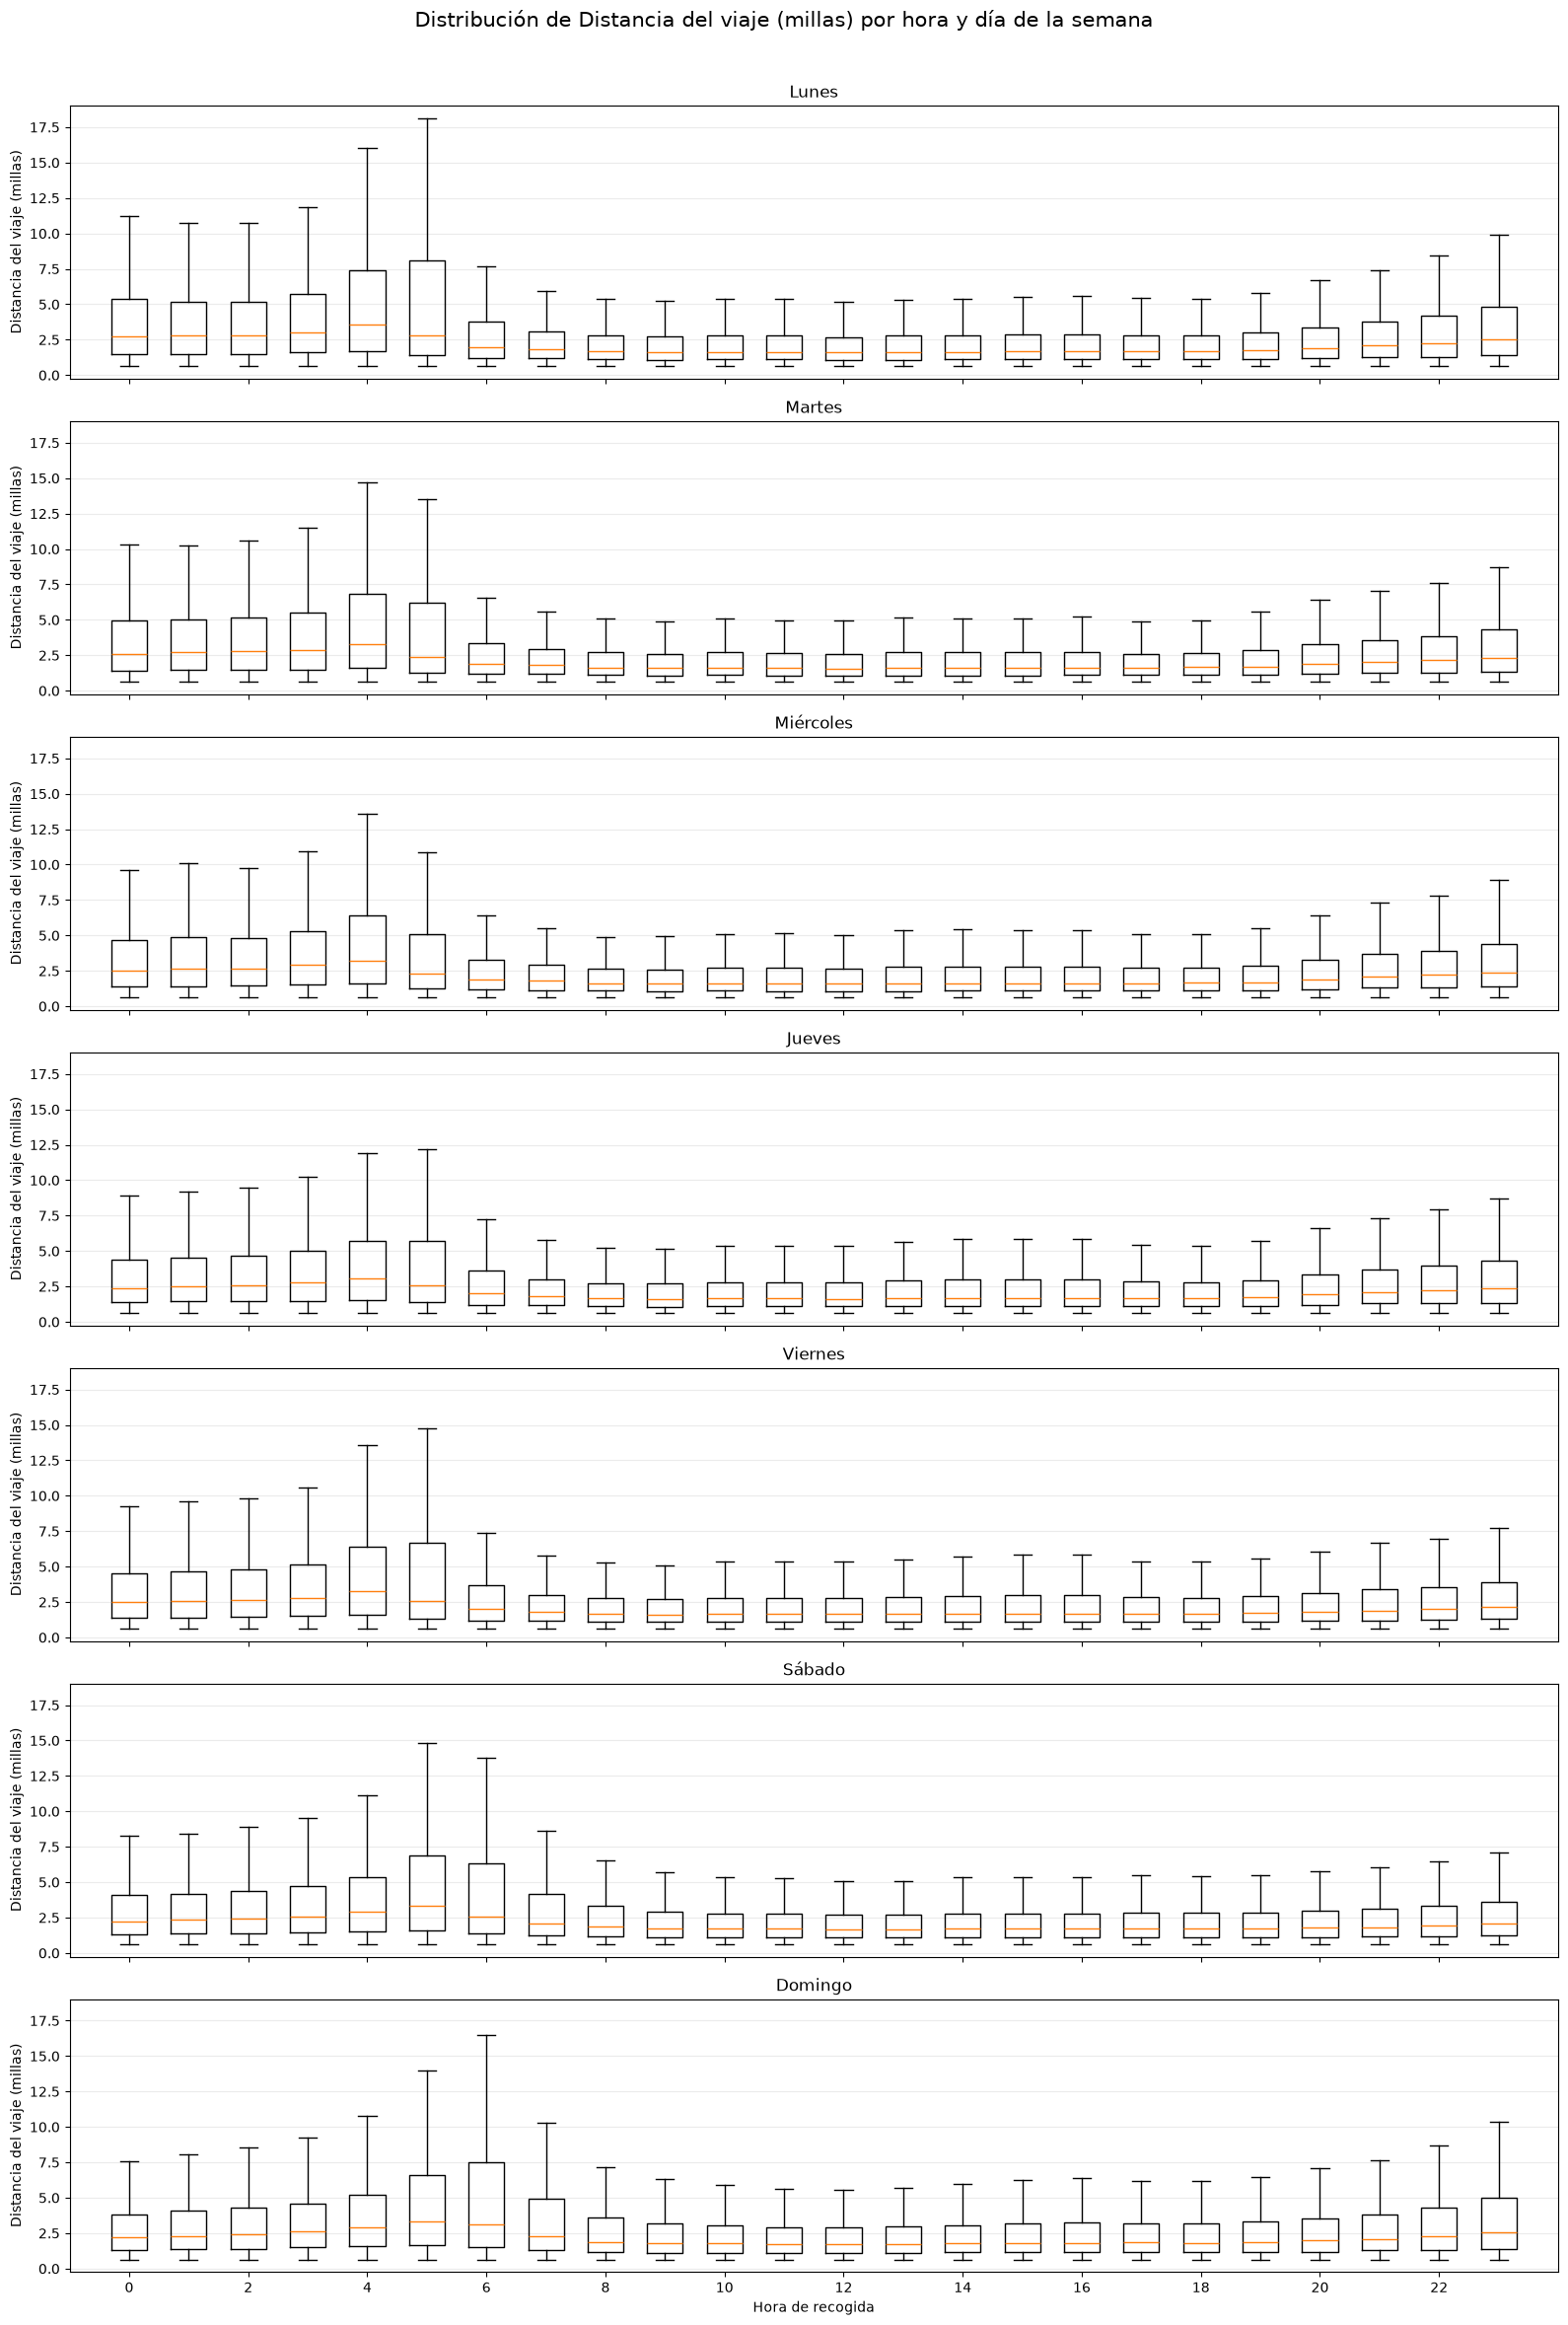

In [11]:
# ============================================================
# BOXPLOTS DE DISTANCIA POR HORA Y DÍA
# ============================================================
fig_boxplot, _ = plot_boxplot_facets(stats_df, 'Distancia del viaje (millas)')

_ = save_figure(fig_boxplot, '01_trip_distance_boxplots', images_dir)

#### Lectura de la distribución temporal

Los diagramas de caja muestran un patrón temporal consistente. Las distancias medianas son mayores durante la madrugada, especialmente entre aproximadamente las **04:00 y las 06:00**, mientras que durante buena parte del horario diurno se estabilizan en valores cercanos a **1,6–1,9 millas**.

Al final del día se observa nuevamente un aumento progresivo de las distancias. Las primeras horas presentan además una mayor dispersión, con bigotes superiores más amplios, lo que indica una mayor heterogeneidad en los trayectos realizados durante esas franjas.

La similitud de las medianas diurnas entre días contrasta con las diferencias observadas en las horas nocturnas y de madrugada.

El cálculo pesado permanece en Spark, mientras que la visualización trabaja sobre el resultado agregado, considerablemente más pequeño que el **dataset distribuido de referencia**.

## 4. Agregaciones temporales y patrones de movilidad

### 4.1. Métrica derivada: importe por milla

Antes de realizar la agregación se incorpora una métrica adicional: el **importe total por milla recorrida**.

Esta variable expresa el **importe total registrado por unidad de distancia**, permitiendo comparar viajes de distinta longitud y complementando el análisis de distancia, velocidad y volumen de desplazamientos.

In [12]:
# ============================================================
# IMPORTE TOTAL POR MILLA
# ============================================================
# Se evita la división por cero devolviendo NULL cuando la distancia recorrida sea igual a cero.
df_with_amount_per_mile = (
    nyc_trips_df
    .withColumn(
        'total_amount_per_mile',
        F.when(
            F.col('trip_distance') != 0, F.col('total_amount') / F.col('trip_distance')
        ).otherwise(None)
    )
)

# ============================================================
# MUESTRA DE LA MÉTRICA DERIVADA
# ============================================================
amount_per_mile_preview_pd = df_with_amount_per_mile.select(
    'trip_distance',
    'fare_amount',
    'total_amount',
    F.round('total_amount_per_mile', 2).alias('total_amount_per_mile')
).limit(15).toPandas()

amount_per_mile_preview_pd.index = range(1, len(amount_per_mile_preview_pd) + 1)

amount_per_mile_preview_pd.index.name = 'Viaje'

amount_per_mile_preview_pd

,trip_distance,fare_amount,total_amount,total_amount_per_mile
Viaje,,,,
1,1.59,12.0,17.05,10.72
2,3.30,14.5,17.80,5.39
3,1.80,9.5,10.80,6.00
4,3.00,15.0,16.30,5.43
5,9.00,27.0,40.33,4.48
6,2.20,14.0,15.30,6.95
7,0.80,7.0,9.96,12.45
8,18.20,52.0,58.13,3.19
9,0.90,6.5,9.35,10.39


### 4.2. Agregación multidimensional por día y hora

Para estudiar los patrones temporales de movilidad se realiza una única agregación distribuida sobre los viajes, agrupando por **día de la semana** y reorganizando las **24 horas del día** mediante una operación `pivot`.

Para cada combinación de día y hora se calculan simultáneamente:

- número de viajes;
- mediana de la distancia recorrida;
- mediana del importe total por milla;
- mediana de la velocidad.

La estrategia permite obtener las distintas métricas a partir de una única operación de agregación sobre el dataset distribuido.

Posteriormente, los resultados agregados se transforman en pequeñas matrices de 7 × 24 valores, adecuadas para su traslado al driver y su representación mediante mapas de calor.

In [13]:
# ============================================================
# AGREGACIÓN DISTRIBUIDA
# ============================================================
# Conteo y medianas se obtienen en una única agregación distribuida
metrics = [
    'trip_distance',
    'total_amount_per_mile',
    'speed',
]

# El resultado se cachea porque alimentará cuatro matrices temporales
counts_and_distances_df = compute_hourly_medians_and_counts(
    df_with_amount_per_mile, metrics
).cache()

### 4.3. Validación y preparación de las matrices temporales

El resultado de la agregación debe contener una fila por cada día de la semana y, para cada una de las 24 horas, cuatro métricas: número de viajes y las medianas de distancia, importe por milla y velocidad.

Esto produce un DataFrame distribuido de **7 filas y 97 columnas**.

A partir de este resultado se construyen cuatro matrices independientes de **7 × 24 valores**, que posteriormente se trasladan a Pandas para su representación.

Antes de continuar se comprueban:

- las dimensiones del DataFrame agregado;
- las columnas esperadas;
- la conversión correcta a Pandas;
- el orden cronológico de los días;
- la presencia de las 24 horas en cada matriz.

In [14]:
# ============================================================
# VALIDACIÓN DE LA AGREGACIÓN
# ============================================================
aggregated_rows = counts_and_distances_df.count()
aggregated_columns = len(counts_and_distances_df.columns)

assert aggregated_rows == 7
assert aggregated_columns == 97
assert 'day_of_week' in counts_and_distances_df.columns

print(f'Filas    : {aggregated_rows}')
print(f'Columnas : {aggregated_columns}')
print('Agregación temporal validada correctamente.')


# ============================================================
# VISTA COMPACTA DE LA AGREGACIÓN
# ============================================================
aggregation_preview_df = counts_and_distances_df.select(
    'day_of_week',
    F.col('8_n_trips').alias('08h · viajes'),
    F.col('8_trip_distance').alias('08h · distancia'),
    F.col('8_total_amount_per_mile').alias('08h · importe/milla'),
    F.col('8_speed').alias('08h · velocidad'),

    F.col('18_n_trips').alias('18h · viajes'),
    F.col('18_trip_distance').alias('18h · distancia'),
    F.col('18_total_amount_per_mile').alias('18h · importe/milla'),
    F.col('18_speed').alias('18h · velocidad'),

    F.col('23_n_trips').alias('23h · viajes'),
    F.col('23_trip_distance').alias('23h · distancia'),
    F.col('23_total_amount_per_mile').alias('23h · importe/milla'),
    F.col('23_speed').alias('23h · velocidad'),
)

# Cada resultado contiene solo 7 filas × 24 horas, por lo que su traslado al driver es seguro
aggregation_preview_pd = (
    aggregation_preview_df
    .toPandas()
    .set_index('day_of_week')
    .reindex(DAYS_ORDER)
)

aggregation_preview_pd.index = [DAY_LABELS[day] for day in aggregation_preview_pd.index]

aggregation_preview_pd.index.name = 'Día'

aggregation_preview_pd

Filas    : 7
Columnas : 97
Agregación temporal validada correctamente.


,08h · viajes,08h · distancia,08h · importe/milla,08h · velocidad,18h · viajes,18h · distancia,18h · importe/milla,18h · velocidad,23h · viajes,23h · distancia,23h · importe/milla,23h · velocidad
Día,,,,,,,,,,,,
Lunes,73142,1.69,6.666667,9.79,74249,1.70,6.625000,11.11,35002,2.50,5.159011,15.76
Martes,68104,1.65,6.969697,8.94,88531,1.66,7.138554,10.25,51661,2.34,5.378151,14.83
Miércoles,89555,1.60,7.062500,8.84,101881,1.68,7.357143,9.40,63587,2.40,5.375940,14.45
Jueves,96884,1.66,6.986301,9.00,119394,1.70,7.235294,9.49,94874,2.34,5.530303,13.70
Viernes,93941,1.69,6.991870,8.82,129079,1.70,7.181818,9.61,127016,2.15,5.880952,12.18
Sábado,48599,1.90,5.470588,14.40,128679,1.70,6.285714,10.28,130114,2.07,5.971223,11.84
Domingo,29727,1.90,5.320000,15.55,79170,1.83,5.866667,11.77,44979,2.56,5.051195,16.26


La vista compacta confirma que la agregación conserva de forma coherente las cuatro métricas calculadas para cada combinación de día y hora.

Las franjas seleccionadas permiten anticipar los patrones que se desarrollan en los mapas de calor: la actividad aumenta notablemente durante la tarde en los últimos días laborables y durante el sábado, mientras que las velocidades medianas son generalmente menores en las horas de mayor concentración de viajes.

In [15]:
# ============================================================
# COLUMNAS PARA LAS MATRICES TEMPORALES
# ============================================================
# Se selecciona la mediana de la distancia para cada hora.
cols_trip_distance = (
    [F.col('day_of_week')] +
    [F.col(f'{hour}_trip_distance').alias(str(hour)) for hour in range(24)]
)

# Se selecciona la mediana del importe por milla para cada hora.
cols_total_amount_per_mile = (
    [F.col('day_of_week')]
    + [F.col(f'{hour}_total_amount_per_mile').alias(str(hour)) for hour in range(24)]
)

# Se selecciona el número de viajes para cada hora.
cols_n_trips = (
    [F.col('day_of_week')]
    + [F.col(f'{hour}_n_trips').alias(str(hour)) for hour in range(24)]
)

# Se selecciona la mediana de la velocidad para cada hora.
cols_speed = (
    [F.col('day_of_week')]
    + [F.col(f'{hour}_speed').alias(str(hour)) for hour in range(24)]
)


# ============================================================
# CONVERSIÓN DE RESULTADOS AGREGADOS A PANDAS
# ============================================================
# Cada resultado contiene únicamente 7 filas y 25 columnas, por lo que se traslada al driver.
trip_distance_by_hour_pd = counts_and_distances_df.select(*cols_trip_distance).toPandas()

total_amount_by_hour_pd = counts_and_distances_df.select(*cols_total_amount_per_mile).toPandas()

n_trips_by_hour_pd = counts_and_distances_df.select(*cols_n_trips).toPandas()

speed_by_hour_pd = counts_and_distances_df.select(*cols_speed).toPandas()


# ============================================================
# ORDEN TEMPORAL DE LOS DÍAS
# ============================================================
# Se aplica el mismo orden a los cuatro DataFrames de Pandas.
trip_distance_by_hour_pd = (
    trip_distance_by_hour_pd.set_index('day_of_week').reindex(DAYS_ORDER).reset_index()
)

total_amount_by_hour_pd = (
    total_amount_by_hour_pd.set_index('day_of_week').reindex(DAYS_ORDER).reset_index()
)

n_trips_by_hour_pd = n_trips_by_hour_pd.set_index('day_of_week').reindex(DAYS_ORDER).reset_index()

speed_by_hour_pd = speed_by_hour_pd.set_index('day_of_week').reindex(DAYS_ORDER).reset_index()


# ============================================================
# VALIDACIÓN DE MATRICES TEMPORALES
# ============================================================
expected_shape = (7, 25)

temporal_matrices = {
    'Distancia mediana': trip_distance_by_hour_pd,
    'Importe por milla': total_amount_by_hour_pd,
    'Número de viajes': n_trips_by_hour_pd,
    'Velocidad mediana': speed_by_hour_pd,
}

matrix_validation_rows = []

for name, matrix in temporal_matrices.items():
    shape_ok = matrix.shape == expected_shape

    days_ok = list(matrix['day_of_week']) == DAYS_ORDER

    hours_ok = all(str(hour) in matrix.columns for hour in range(24))

    matrix_ok = (shape_ok and days_ok and hours_ok)

    assert matrix_ok

    matrix_validation_rows.append({
        'Matriz': name,
        'Filas': matrix.shape[0],
        'Horas': 24,
        'Orden días': 'Lunes → Domingo',
        'Estado': 'OK' if matrix_ok else 'REVISAR'
    })

matrix_validation_pd = pd.DataFrame(
    matrix_validation_rows
).set_index('Matriz')

matrix_validation_pd

,Filas,Horas,Orden días,Estado
Matriz,,,,
Distancia mediana,7,24,Lunes → Domingo,OK
Importe por milla,7,24,Lunes → Domingo,OK
Número de viajes,7,24,Lunes → Domingo,OK
Velocidad mediana,7,24,Lunes → Domingo,OK


### 4.4. Patrones semanales mediante mapas de calor

Las matrices agregadas permiten visualizar conjuntamente las variaciones horarias y semanales de las principales métricas del sistema de movilidad.

Los mapas de calor muestran:

- distancia mediana de los viajes;
- importe mediano por milla;
- volumen de viajes;
- velocidad mediana.

El procesamiento sobre millones de registros se realiza previamente en Spark. La representación utiliza únicamente las matrices agregadas resultantes.

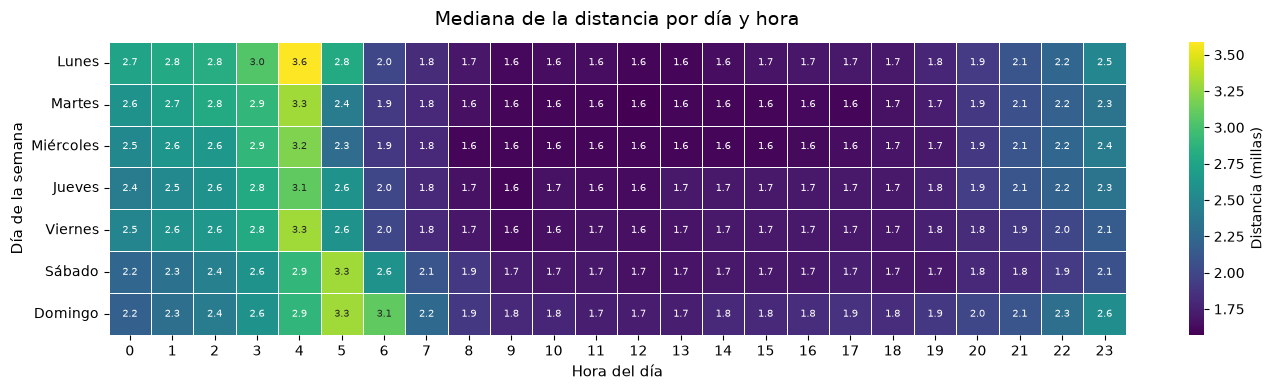

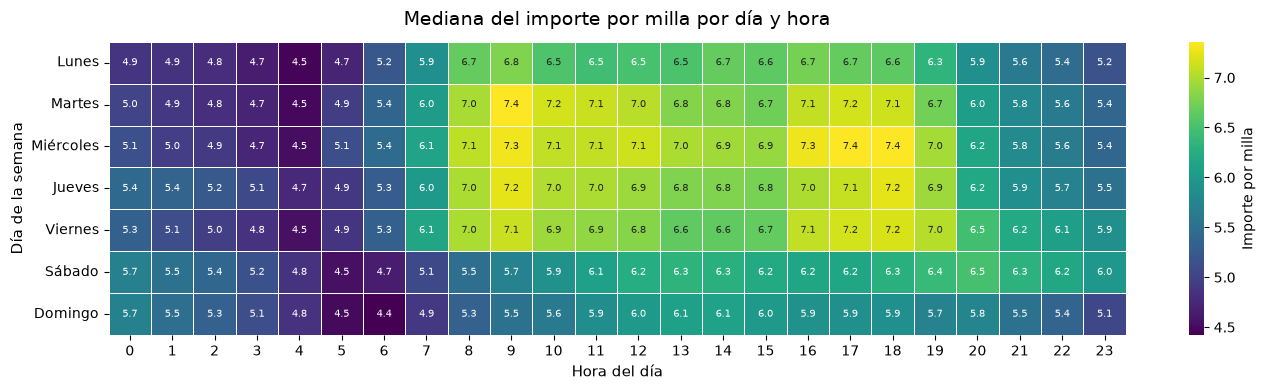

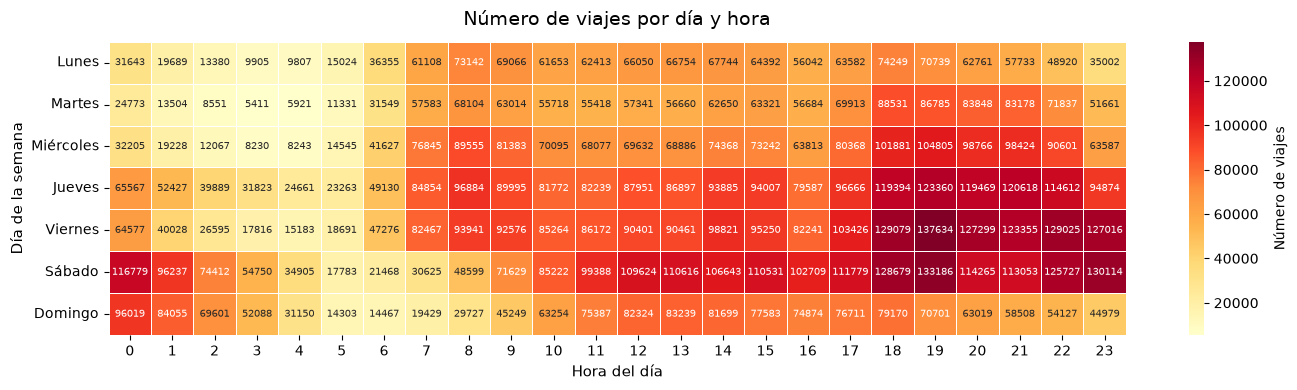

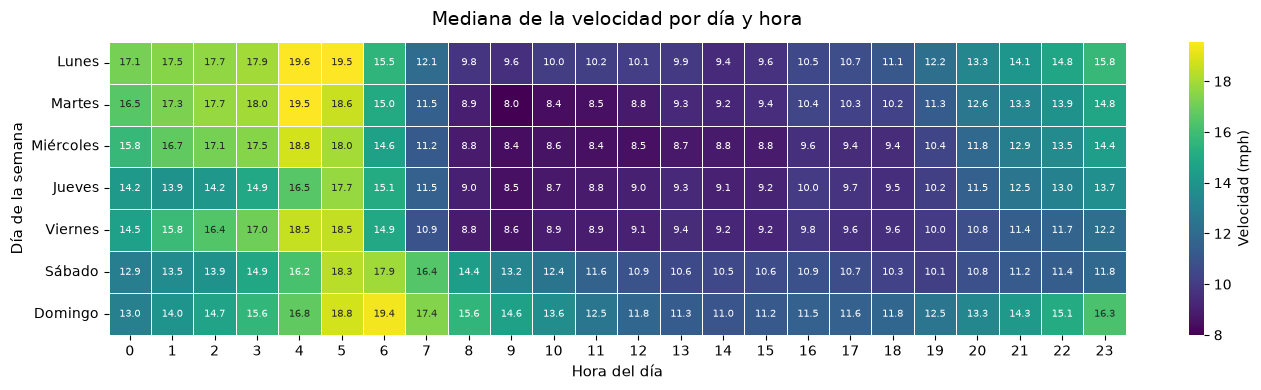

In [16]:
fig_distance, _ = plot_week_hour_heatmap(
    trip_distance_by_hour_pd, title='Mediana de la distancia por día y hora',
    cbar_label='Distancia (millas)', cmap='viridis', fmt='.1f'
)
_ = save_figure(fig_distance, '02_heatmap_trip_distance', images_dir)

fig_distance, _ = plot_week_hour_heatmap(
    total_amount_by_hour_pd, title='Mediana del importe por milla por día y hora',
    cbar_label='Importe por milla', cmap='viridis', fmt='.1f'
)
_ = save_figure(fig_distance, '03_heatmap_amount_per_mile', images_dir)

fig_distance, _ = plot_week_hour_heatmap(
    n_trips_by_hour_pd, title='Número de viajes por día y hora',
    cbar_label='Número de viajes', cmap='YlOrRd', fmt='.0f'
)
_ = save_figure(fig_distance, '04_heatmap_trip_count', images_dir)

fig_distance, _ = plot_week_hour_heatmap(
    speed_by_hour_pd, title='Mediana de la velocidad por día y hora',
    cbar_label='Velocidad (mph)', cmap='viridis', fmt='.1f'
)
_ = save_figure(fig_distance, '05_heatmap_speed', images_dir)


#### Lectura de los patrones temporales

Los cuatro mapas de calor muestran comportamientos complementarios:

- la **distancia mediana** aumenta durante la madrugada y disminuye durante las horas centrales del día;
- el **importe por milla** es mayor durante buena parte del horario diurno de los días laborables y menor en determinadas franjas nocturnas;
- el **volumen de viajes** se concentra especialmente entre el jueves y el sábado, con máximos durante la tarde y la noche;
- la **velocidad mediana** aumenta en las franjas con menor demanda y disminuye durante las horas de mayor actividad urbana.

La combinación de estas métricas muestra la relación entre demanda y condiciones de circulación: las franjas con mayor concentración de viajes tienden a presentar velocidades medianas inferiores, mientras que las horas nocturnas y de madrugada presentan trayectos más rápidos y, en determinados momentos, más largos.

### 4.5. Volumen total de viajes por día

Los mapas de calor anteriores permiten analizar simultáneamente la dimensión horaria y semanal de la movilidad.

Como visión complementaria, se agrega el número de viajes de las 24 horas para obtener el **volumen total registrado en cada día de la semana**.

Esta representación simplificada permite comparar directamente la demanda diaria y facilita la identificación de diferencias globales entre días laborables y fin de semana, mientras que los mapas de calor conservan el detalle necesario para estudiar cómo se distribuye esa actividad a lo largo del día.

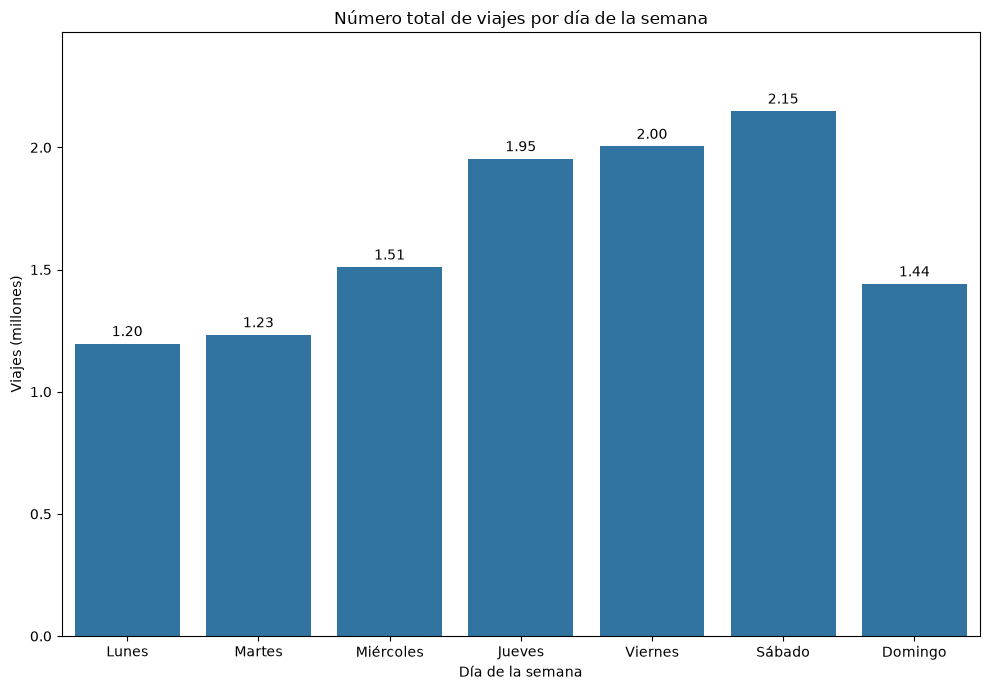

In [17]:
# ============================================================
# AGREGACIÓN DEL VOLUMEN DIARIO
# ============================================================
daily_trips_pd = (
    n_trips_by_hour_pd
    .set_index('day_of_week')
    .sum(axis=1)
    .reindex(DAYS_ORDER)
    .div(1_000_000)
    .reset_index(name='n_trips_millions')
)


# ============================================================
# VOLUMEN TOTAL DE VIAJES POR DÍA
# ============================================================
fig, ax = plt.subplots(figsize=(10, 7))

sns.barplot(data=daily_trips_pd, x='day_of_week', y='n_trips_millions', ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt='{:,.2f}', padding=3)

ax.set_title('Número total de viajes por día de la semana')
ax.set_xlabel('Día de la semana')
ax.set_ylabel('Viajes (millones)')

ax.set_xticks(range(len(DAYS_ORDER)))
ax.set_xticklabels([DAY_LABELS[day] for day in DAYS_ORDER])
ax.tick_params(axis='x', rotation=0)

ax.margins(y=0.15)

fig.tight_layout()

_ = save_figure(fig, '06_daily_trip_volume', images_dir)

plt.show()

#### Lectura del volumen semanal

El **sábado** registra el mayor volumen del periodo, con aproximadamente **2,15 millones de viajes**, seguido del viernes (**2,00 millones**) y el jueves (**1,95 millones**).

El lunes presenta el menor volumen, con aproximadamente **1,20 millones**, mientras que el domingo desciende hasta **1,44 millones** después del máximo del sábado.

El patrón confirma que la demanda no evoluciona únicamente según la distinción laborable/fin de semana: aumenta progresivamente durante la segunda mitad de la semana, alcanza su máximo el sábado y se reduce de forma clara el domingo.

## 5. Preparación y exploración geoespacial

### 5.1. Distritos comunitarios de Nueva York

El análisis geoespacial incorpora los límites de los **distritos comunitarios de Nueva York (NYC Community Districts)** a partir de un fichero GeoJSON.

Debido al reducido tamaño de esta información territorial, los polígonos se cargan mediante **GeoPandas**, mientras que el dataset principal de viajes permanece distribuido en Spark.

El GeoDataFrame resultante contiene la geometría de cada distrito y se enriquece con su denominación mediante el identificador `BoroCD`.

Esta representación geográfica se utilizará posteriormente para realizar operaciones espaciales distribuidas con **Apache Sedona**.

In [18]:
# ============================================================
# REFERENCIA DE DISTRITOS
# ============================================================
districts_pd = pd.read_csv(io.StringIO(DISTRICTS_REFERENCE), names=['BoroCD', 'district'])


# ============================================================
# CARGA DE GEOMETRÍAS
# ============================================================
if not geojson_path.exists():
    raise FileNotFoundError(f'No se encuentra el fichero geográfico: {geojson_path}')

# El GeoJSON contiene los polígonos de los distritos comunitarios
gdf_raw = gpd.read_file(geojson_path)

# Los nombres se incorporan mediante el identificador BoroCD
nyc_gdf = gdf_raw.merge(districts_pd, on='BoroCD', how='inner')


# ============================================================
# RESUMEN DE LA CARGA GEOGRÁFICA
# ============================================================
geometry_load_summary_pd = pd.DataFrame({
    'Indicador': [
        'Fichero',
        'Geometrías leídas',
        'Distritos enlazados',
        'BoroCD únicos',
        'CRS',
        'Tipo geométrico'
    ],
    'Valor': [
        geojson_path.name,
        len(gdf_raw),
        len(nyc_gdf),
        nyc_gdf['BoroCD'].nunique(),
        str(nyc_gdf.crs),
        ', '.join(sorted(nyc_gdf.geom_type.unique()))
    ]
}).set_index('Indicador')

geometry_load_summary_pd

,Valor
Indicador,
Fichero,NYC_Community_Districts.geojson
Geometrías leídas,71
Distritos enlazados,59
BoroCD únicos,59
CRS,EPSG:4326
Tipo geométrico,"MultiPolygon, Polygon"


### 5.2. Validación de la información territorial

Antes de utilizar las geometrías en las operaciones espaciales se comprueba que el GeoDataFrame contiene los identificadores, nombres y geometrías necesarios para representar los distritos y construir posteriormente el DataFrame espacial de Spark.

In [19]:
# ============================================================
# VALIDACIÓN DE LA INFORMACIÓN TERRITORIAL
# ============================================================
required_geo_columns = {
    'BoroCD',
    'district',
    'geometry',
}

assert required_geo_columns.issubset(nyc_gdf.columns)
assert isinstance(nyc_gdf, gpd.GeoDataFrame)
assert not nyc_gdf.empty
assert nyc_gdf.geometry.notna().all()

borough_names = {
    1: 'Manhattan',
    2: 'Bronx',
    3: 'Brooklyn',
    4: 'Queens',
    5: 'Staten Island'
}

territorial_validation_pd = pd.DataFrame({
    'BoroCD': nyc_gdf['BoroCD'],
    'Borough': (nyc_gdf['BoroCD'].floordiv(100).map(borough_names)),
    'Distrito': nyc_gdf['district'],
    'Geometría': nyc_gdf.geom_type,
    'Válida': nyc_gdf.geometry.is_valid,
    'Vacía': nyc_gdf.geometry.is_empty
})

territorial_validation_pd = (
    territorial_validation_pd.sort_values('BoroCD').set_index('BoroCD')
)

territorial_validation_pd

,Borough,Distrito,Geometría,Válida,Vacía
BoroCD,,,,,
101,Manhattan,Financial District (CD1),MultiPolygon,True,False
102,Manhattan,Greenwich Village and Soho (CD2),Polygon,True,False
103,Manhattan,Lower East Side and Chinatown (CD3),Polygon,True,False
104,Manhattan,Clinton and Chelsea (CD4),Polygon,True,False
105,Manhattan,Midtown (CD5),Polygon,True,False
106,Manhattan,Stuyvesant Town and Turtle Bay (CD6),MultiPolygon,True,False
107,Manhattan,Upper West Side (CD7),Polygon,True,False
108,Manhattan,Upper East Side (CD8),MultiPolygon,True,False
109,Manhattan,Morningside Heights and Hamilton Heights (CD9),Polygon,True,False


In [20]:
# ============================================================
# MUESTREO CARTOGRÁFICO
# ============================================================
sample_fraction = 0.002 / 100

viajes_pd = (
    nyc_trips_df
    # Solo se traslada al driver una muestra reproducible destinada a la representación
    .sample(
        withReplacement=False,
        fraction=sample_fraction,
        seed=random_seed
    )
    .limit(1000)
    .select(
        'pickup_latitude',
        'pickup_longitude',
        'dropoff_latitude',
        'dropoff_longitude'
    )
    .toPandas()
)


# ============================================================
# VALIDACIÓN DE LA MUESTRA
# ============================================================
expected_sample_size = round(trip_count * sample_fraction)

sample_tolerance = max(30, round(expected_sample_size * 0.20))

sample_difference = len(viajes_pd) - expected_sample_size

expected_sample_columns = [
    'pickup_latitude',
    'pickup_longitude',
    'dropoff_latitude',
    'dropoff_longitude'
]

sample_size_ok = abs(sample_difference) <= sample_tolerance

sample_columns_ok = list(viajes_pd.columns) == expected_sample_columns

sample_validation_ok = sample_size_ok and sample_columns_ok

assert sample_size_ok
assert sample_columns_ok

sample_validation_pd = pd.DataFrame({
    'Indicador': [
        'Fracción solicitada',
        'Registros esperados',
        'Registros obtenidos',
        'Diferencia',
        'Tolerancia',
        'Columnas geográficas',
        'Columnas correctas',
        'Estado'
    ],
    'Valor': [
        f'{sample_fraction * 100:.3f} %',
        expected_sample_size,
        len(viajes_pd),
        sample_difference,
        f'± {sample_tolerance}',
        len(viajes_pd.columns),
        'Sí' if sample_columns_ok else 'No',
        'OK' if sample_validation_ok else 'REVISAR'
    ]
}).set_index('Indicador')

sample_validation_pd

,Valor
Indicador,
Fracción solicitada,0.002 %
Registros esperados,230
Registros obtenidos,228
Diferencia,-2
Tolerancia,± 46
Columnas geográficas,4
Columnas correctas,Sí
Estado,OK


#### Comprobación territorial

La lectura inicial del GeoJSON contiene **71 geometrías**. Tras incorporar la tabla de referencia mediante `BoroCD`, el análisis conserva **59 distritos comunitarios únicos**, que constituyen las unidades territoriales utilizadas en los spatial joins posteriores.

Las geometrías enlazadas se representan como `Polygon` o `MultiPolygon` y mantienen el sistema de referencia geográfica **EPSG:4326**, compatible con las coordenadas de longitud y latitud de los viajes.

La tabla de validación permite comprobar individualmente el tipo geométrico, su validez y la ausencia de geometrías vacías antes de trasladar esta información a Spark.

### 5.3. Exploración cartográfica

Para comprobar visualmente la cobertura territorial de los datos se representan los límites de los distritos junto con una muestra de ubicaciones de los viajes.

La representación utiliza **Folium** a través de la función auxiliar `plot_community_districts_map`. El dataset completo permanece en Spark y únicamente la pequeña muestra preparada anteriormente se utiliza para construir el mapa interactivo.

In [21]:
# ============================================================
# VISUALIZACIÓN EN FOLIUM
# ============================================================
# Se representan los distritos y los puntos de recogida correspondientes a la muestra.
nyc_map = plot_community_districts_map(nyc_gdf, viajes_pd)


# ============================================================
# EXPORTACIÓN DEL MAPA INTERACTIVO
# ============================================================
map_output_path = outputs_dir / 'nyc_community_districts_map.html'

nyc_map.save(str(map_output_path))

# Visualización interactiva desactivada en la versión pública de GitHub.
# El mapa completo se exporta como archivo HTML.
# nyc_map

In [22]:
# ============================================================
# VALIDACIÓN DE LA VISUALIZACIÓN
# ============================================================
assert nyc_map.__class__.__name__ == 'Map'

print('Mapa interactivo generado correctamente.')

Mapa interactivo generado correctamente.


#### Lectura cartográfica

La información territorial incorpora **59 distritos comunitarios** en el sistema de referencia `EPSG:4326`.

El mapa superpone estos límites con una muestra reproducible de puntos de recogida para comprobar visualmente la coherencia de las coordenadas y su relación con la geometría urbana.

La muestra se utiliza exclusivamente con fines exploratorios y de validación visual; los spatial joins posteriores se realizan sobre el dataset distribuido completo.

## 6. Procesamiento geoespacial distribuido con Apache Sedona

### 6.1. Geometrías espaciales en Spark

Una vez preparada la información territorial, el siguiente objetivo es determinar el distrito comunitario correspondiente a los puntos de recogida y destino de cada viaje.

Para realizar esta operación sobre el dataset distribuido se utiliza **Apache Sedona**, extensión geoespacial de Spark que permite incorporar geometrías y ejecutar predicados espaciales directamente sobre DataFrames.

El flujo combina:

- polígonos de los distritos convertidos desde GeoPandas a geometrías Sedona;
- puntos de recogida y destino creados a partir de longitud y latitud;
- `ST_Contains` como predicado espacial;
- `broadcast joins` para distribuir la pequeña tabla territorial entre los executors;
- `left joins` para conservar todos los registros de viajes aunque alguna coordenada no pueda asignarse a un distrito.

El resultado incorpora a cada viaje las columnas `pickup_district` y `dropoff_district`.

### 6.2. Conversión de polígonos a geometrías Sedona

Las geometrías de los distritos se encuentran inicialmente en un `GeoDataFrame`.

Para trasladarlas a Spark se serializan temporalmente en formato **WKT (Well-Known Text)** y posteriormente se reconstruyen como objetos geométricos mediante `ST_GeomFromWKT`.

De esta forma, los polígonos quedan disponibles para operaciones espaciales distribuidas dentro de Spark.

In [23]:
# ============================================================
# POLÍGONOS DE LOS DISTRITOS
# ============================================================
# GeoPandas mantiene las geometrías localmente; se serializan a WKT para trasladarlas a Spark
nyc_gdf['district_geom'] = nyc_gdf['geometry'].apply(lambda geometry: geometry.wkt)

# Sedona reconstruye el WKT como geometría espacial
districts_df = (
    spark
    .createDataFrame(nyc_gdf[['district', 'district_geom']])
    .withColumn('district_geom', F.expr('ST_GeomFromWKT(district_geom)'))
)

districts_df.printSchema()

root
 |-- district: string (nullable = true)
 |-- district_geom: geometry (nullable = true)



### 6.3. Construcción de puntos espaciales

Las coordenadas de cada viaje se transforman en geometrías puntuales mediante `ST_Point`.

La función utiliza el orden espacial convencional:

**X = longitud**  
**Y = latitud**

Se generan dos geometrías por viaje, correspondientes al punto de recogida y al punto de destino.

In [24]:
# ============================================================
# PUNTOS DE RECOGIDA Y DESTINO
# ============================================================
trips_with_points = (
    nyc_trips_df
    # ST_Point utiliza el orden X/Y: longitud primero, latitud después
    .withColumn('pickup_point', F.expr('ST_Point(pickup_longitude, pickup_latitude)'))
    .withColumn('dropoff_point', F.expr('ST_Point(dropoff_longitude, dropoff_latitude)'))
)

# ============================================================
# MUESTRA DE GEOMETRÍAS PUNTUALES
# ============================================================
points_preview_pd = (
    trips_with_points
    .select(
        'pickup_longitude',
        'pickup_latitude',
        'dropoff_longitude',
        'dropoff_latitude',
        'trip_distance',
        F.expr('ST_AsText(pickup_point)').alias('pickup_point'),
        F.expr('ST_AsText(dropoff_point)').alias('dropoff_point'),
    )
    .limit(15)
    .toPandas()
)

coordinate_columns = [
    'pickup_longitude',
    'pickup_latitude',
    'dropoff_longitude',
    'dropoff_latitude'
]

points_preview_pd.index = range(1, len(points_preview_pd) + 1)

points_preview_pd.index.name = 'Viaje'

points_preview_pd[coordinate_columns] = points_preview_pd[coordinate_columns].round(5)

points_preview_pd

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_distance,pickup_point,dropoff_point
Viaje,,,,,,,
1,-73.99390,40.75011,-73.97478,40.75062,1.59,POINT (-73.993896484375 40.7501106262207),POINT (-73.97478485107422 40.75061798095703)
2,-74.00165,40.72424,-73.99442,40.75911,3.30,POINT (-74.00164794921875 40.7242431640625),POINT (-73.99441528320312 40.75910949707031)
3,-73.96334,40.80279,-73.95182,40.82441,1.80,POINT (-73.96334075927734 40.80278778076172),POINT (-73.95182037353516 40.82441329956055)
4,-73.97118,40.76243,-74.00418,40.74265,3.00,POINT (-73.97117614746094 40.762428283691406),POINT (-74.00418090820312 40.742652893066406)
5,-73.87437,40.77405,-73.98698,40.75819,9.00,POINT (-73.87437438964844 40.7740478515625),POINT (-73.98697662353516 40.75819396972656)
6,-73.98328,40.72601,-73.99247,40.74963,2.20,POINT (-73.9832763671875 40.726009368896484),POINT (-73.99246978759766 40.7496337890625)
7,-74.00266,40.73414,-73.99501,40.72633,0.80,POINT (-74.0026626586914 40.7341423034668),POINT (-73.99501037597656 40.72632598876953)
8,-73.78304,40.64436,-73.98759,40.75936,18.20,POINT (-73.78304290771484 40.64435577392578),POINT (-73.98759460449219 40.75935745239258)
9,-73.98559,40.76795,-73.98592,40.75937,0.90,POINT (-73.98558807373047 40.767948150634766),POINT (-73.98591613769531 40.75936508178711)


### 6.4. Spatial joins mediante `ST_Contains`

El distrito correspondiente a cada coordenada se obtiene comprobando qué polígono contiene cada punto mediante `ST_Contains`.

La tabla de distritos es muy pequeña frente al dataset de viajes, por lo que se utiliza `broadcast` para distribuirla entre los executors y evitar un movimiento innecesario de la tabla principal.

Los joins se realizan como `left join` para conservar los viajes aunque una coordenada no se encuentre dentro de ninguno de los polígonos disponibles.

In [25]:
# ============================================================
# DISTRITOS PARA LOS SPATIAL JOINS
# ============================================================
pickup_districts = districts_df.withColumnRenamed('district', 'pickup_district')

dropoff_districts = districts_df.withColumnRenamed('district', 'dropoff_district')


# ============================================================
# DISTRITO DE RECOGIDA
# ============================================================
trips_pickup = (
    trips_with_points
    # La tabla de distritos es pequeña y se distribuye mediante broadcast
    # para evitar redistribuir el DataFrame principal de viajes
    .join(
        F.broadcast(pickup_districts),
        F.expr('ST_Contains(district_geom, pickup_point)'),
        how='left'
    )
    .drop('pickup_point', 'district_geom')
)


# ============================================================
# DISTRITO DE DESTINO
# ============================================================
nyc_trips_with_districts = (
    trips_pickup
    # El segundo spatial join incorpora el distrito de destino
    # manteniendo la misma estrategia que para el pickup
    .join(
        F.broadcast(dropoff_districts),
        F.expr('ST_Contains(district_geom, dropoff_point)'),
        how='left'
    )
    .drop('dropoff_point', 'district_geom')
)


# ============================================================
# RESUMEN DE LOS SPATIAL JOINS
# ============================================================
spatial_join_summary_pd = pd.DataFrame({
    'Asignación': [
        'Pickup',
        'Dropoff'
    ],
    'Punto': [
        'pickup_point',
        'dropoff_point'
    ],
    'Resultado': [
        'pickup_district',
        'dropoff_district'
    ],
    'Condición espacial': [
        'ST_Contains(district_geom, pickup_point)',
        'ST_Contains(district_geom, dropoff_point)'
    ],
    'Join': [
        'left',
        'left'
    ],
    'Broadcast': [
        f'{len(nyc_gdf)} polígonos',
        f'{len(nyc_gdf)} polígonos'
    ]
}).set_index('Asignación')

spatial_join_summary_pd

,Punto,Resultado,Condición espacial,Join,Broadcast
Asignación,,,,,
Pickup,pickup_point,pickup_district,"ST_Contains(district_geom, pickup_point)",left,59 polígonos
Dropoff,dropoff_point,dropoff_district,"ST_Contains(district_geom, dropoff_point)",left,59 polígonos


### 6.5. Validación del enriquecimiento espacial

El DataFrame resultante mantiene la información original de los viajes e incorpora los distritos correspondientes a los puntos de recogida y destino.

Las coordenadas que no pueden asociarse a ninguno de los polígonos pueden producir valores nulos; estos registros se conservan deliberadamente.

In [26]:
# ============================================================
# VALIDACIÓN DEL ENRIQUECIMIENTO ESPACIAL
# ============================================================
assert 'pickup_district' in nyc_trips_with_districts.columns
assert 'dropoff_district' in nyc_trips_with_districts.columns

spatial_types = dict(nyc_trips_with_districts.dtypes)


spatial_validation_pd = pd.DataFrame({
    'Columna': [
        'pickup_district',
        'dropoff_district'
    ],
    'Tipo Spark': [
        spatial_types['pickup_district'],
        spatial_types['dropoff_district']
    ],
    'Origen': [
        'pickup_point',
        'dropoff_point'
    ],
    'Condición espacial': [
        'ST_Contains(district_geom, pickup_point)',
        'ST_Contains(district_geom, dropoff_point)'
    ],
    'Estado': [
        'OK' if 'pickup_district' in nyc_trips_with_districts.columns else 'NO',
        'OK' if 'dropoff_district' in nyc_trips_with_districts.columns else 'NO'
    ]
}).set_index('Columna')

print(f'Columnas antes del enriquecimiento : {len(nyc_trips_df.columns)}')

print(f'Columnas después del enriquecimiento: {len(nyc_trips_with_districts.columns)}')

spatial_validation_pd

Columnas antes del enriquecimiento : 23
Columnas después del enriquecimiento: 25


,Tipo Spark,Origen,Condición espacial,Estado
Columna,,,,
pickup_district,string,pickup_point,"ST_Contains(district_geom, pickup_point)",OK
dropoff_district,string,dropoff_point,"ST_Contains(district_geom, dropoff_point)",OK


### 6.6. Dataset espacial de análisis

Una vez completados los spatial joins se conserva únicamente la información necesaria para los análisis territoriales posteriores.

La proyección reduce el número de columnas antes de persistir el resultado, evitando mantener en caché información que ya no será utilizada en esta fase.

In [27]:
# ============================================================
# DATAFRAME ESPACIAL PARA ANÁLISIS
# ============================================================
spatial_analysis_df = nyc_trips_with_districts.select(
    'day_of_week',
    'pickup_district',
    'dropoff_district'
).cache()


# ============================================================
# MUESTRA DEL DATASET ESPACIAL
# ============================================================
spatial_analysis_preview_pd = spatial_analysis_df.limit(15).toPandas()

spatial_analysis_preview_pd['pickup_district'] = (
    spatial_analysis_preview_pd['pickup_district']
    .replace(DISTRICT_LABELS)
)

spatial_analysis_preview_pd['dropoff_district'] = (
    spatial_analysis_preview_pd['dropoff_district']
    .replace(DISTRICT_LABELS)
)

spatial_analysis_preview_pd['day_of_week'] = (
    spatial_analysis_preview_pd['day_of_week']
    .replace(DAY_LABELS)
)

spatial_analysis_preview_pd.index = range(1, len(spatial_analysis_preview_pd) + 1)

spatial_analysis_preview_pd.index.name = 'Viaje'

spatial_analysis_preview_pd

,day_of_week,pickup_district,dropoff_district
Viaje,,,
1,Jueves,Midtown,Stuyvesant / Turtle Bay
2,Sábado,Greenwich / SoHo,Chelsea / Clinton
3,Sábado,Morningside / Hamilton Hts,Morningside / Hamilton Hts
4,Sábado,Midtown,Chelsea / Clinton
5,Sábado,None,Midtown
6,Sábado,LES / Chinatown,Midtown
7,Sábado,Greenwich / SoHo,Greenwich / SoHo
8,Sábado,None,Midtown
9,Sábado,Chelsea / Clinton,Midtown


### 6.7. Cobertura del enriquecimiento espacial

Los spatial joins se realizan mediante `left join`, por lo que todos los viajes se conservan aunque alguna coordenada no pueda asociarse a uno de los polígonos disponibles.

Se cuantifica la **cobertura espacial** obtenida para los puntos de recogida y destino.

La ausencia de distrito no implica necesariamente un registro erróneo: puede corresponder a ubicaciones situadas fuera de la cobertura de los polígonos utilizados. Por este motivo, estos registros se conservan y se contabilizan explícitamente.

In [28]:
# ============================================================
# COBERTURA DEL ENRIQUECIMIENTO ESPACIAL
# ============================================================
spatial_coverage = (
    spatial_analysis_df
    .agg(
        F.count('*').alias('total_trips'),
        F.sum(F.col('pickup_district').isNull().cast('int')).alias('pickup_unassigned'),
        F.sum(F.col('dropoff_district').isNull().cast('int')).alias('dropoff_unassigned'),
        F.sum(
            (
                F.col('pickup_district').isNotNull() & F.col('dropoff_district').isNotNull()
            ).cast('int')
        ).alias('both_assigned')
    )
    .first()
)

spatial_total = spatial_coverage['total_trips']

pickup_unassigned = spatial_coverage['pickup_unassigned']

pickup_assigned = spatial_total - pickup_unassigned

dropoff_unassigned = spatial_coverage['dropoff_unassigned']

dropoff_assigned = spatial_total - dropoff_unassigned

both_assigned = spatial_coverage['both_assigned']

incomplete_assignment = spatial_total - both_assigned


# ============================================================
# VALIDACIÓN DE CONSERVACIÓN
# ============================================================
assert spatial_total == trip_count
assert pickup_unassigned > 0
assert dropoff_unassigned > 0


# ============================================================
# RESUMEN DE COBERTURA ESPACIAL
# ============================================================
spatial_coverage_pd = pd.DataFrame({
    'Asignación': [
        'Pickup',
        'Dropoff',
        'Pickup y dropoff'
    ],
    'Asignados': [
        pickup_assigned,
        dropoff_assigned,
        both_assigned
    ],
    'No asignados / incompletos': [
        pickup_unassigned,
        dropoff_unassigned,
        incomplete_assignment
    ],
    'Cobertura (%)': [
        100 * pickup_assigned / spatial_total,
        100 * dropoff_assigned / spatial_total,
        100 * both_assigned / spatial_total
    ]
}).set_index('Asignación')

spatial_coverage_pd['Cobertura (%)'] = spatial_coverage_pd['Cobertura (%)'].round(2)

print(f'Conservación de filas: {trip_count:,} → {spatial_total:,} · OK')

_ = save_table(spatial_coverage_pd, '02_spatial_coverage', tables_dir)

spatial_coverage_pd

Conservación de filas: 11,489,716 → 11,489,716 · OK


,Asignados,No asignados / incompletos,Cobertura (%)
Asignación,,,
Pickup,10665874,823842,92.83
Dropoff,10927542,562174,95.11
Pickup y dropoff,10318369,1171347,89.81


#### Cobertura obtenida

El enriquecimiento espacial permite asignar un distrito al **92,83 %** de los puntos de recogida y al **95,11 %** de los puntos de destino. En el **89,81 %** de los viajes se dispone simultáneamente de distrito de origen y de destino.

Los registros restantes se conservan debido al uso de `left join`. La ausencia de asignación no se interpreta automáticamente como un error, ya que puede corresponder a coordenadas situadas fuera de la cobertura de los polígonos utilizados.

## 7. Patrones espaciales de movilidad

### 7.1. Viajes iniciados por distrito y día

Una vez asignado un distrito a cada punto de recogida, los viajes se agregan por distrito y día de la semana.

La agregación continúa realizándose en Spark. Solo el resultado final, de tamaño reducido, se convierte a Pandas para facilitar su análisis y representación.

In [29]:
# ============================================================
# VIAJES INICIADOS POR DISTRITO Y DÍA
# ============================================================
trips_per_district_pd = (
    spatial_analysis_df
    .groupBy('pickup_district')
    .pivot('day_of_week', DAYS_ORDER)
    .count()
    # La agregación territorial produce un resultado pequeño, por lo que se traslada a Pandas
    # para su análisis y visualización
    .toPandas()
)


# ============================================================
# ACTIVIDAD SEMANAL POR DISTRITO
# ============================================================
district_activity_pd = trips_per_district_pd.dropna(subset=['pickup_district']).copy()

district_activity_pd[DAYS_ORDER] = district_activity_pd[DAYS_ORDER].fillna(0).astype('int64')

district_activity_pd['total_week'] = district_activity_pd[DAYS_ORDER].sum(axis=1)

district_activity_pd = district_activity_pd.sort_values(
    'total_week', ascending=False
).reset_index(drop=True)

In [30]:
# ============================================================
# DISTRITOS CON MAYOR VOLUMEN SEMANAL
# ============================================================
district_activity_preview_pd = district_activity_pd.head(15)[[
    'pickup_district',
    'total_week',
    *DAYS_ORDER
]].copy()

district_activity_preview_pd['pickup_district'] = (
    district_activity_preview_pd['pickup_district']
    .replace(DISTRICT_LABELS)
)

district_activity_preview_pd = district_activity_preview_pd.rename(
    columns={
        'pickup_district': 'Distrito',
        'total_week': 'Total semanal',
        **{day: DAY_LABELS[day] for day in DAYS_ORDER}
    }
).set_index('Distrito')

_ = save_table(district_activity_preview_pd, '03_top_districts', tables_dir)

district_activity_preview_pd

,Total semanal,Lunes,Martes,Miércoles,Jueves,Viernes,Sábado,Domingo
Distrito,,,,,,,,
Midtown,2742852,295556,324348,399037,481460,481034,457324,304093
Upper East Side,1596827,179780,184973,225675,276765,286010,275583,168041
Chelsea / Clinton,1224867,127392,127252,152962,201189,211313,239224,165535
Stuyvesant / Turtle Bay,1211238,123876,130519,161796,212571,218775,222924,140777
Greenwich / SoHo,1121318,101166,106792,133916,175157,193798,249879,160610
Upper West Side,988038,104769,107412,129201,165950,168531,188380,123795
LES / Chinatown,670702,49574,49185,61021,95861,108028,180767,126266
Financial District,526959,53317,59069,75388,98793,98810,86838,54744
East Harlem,99715,10962,10380,11789,16822,18192,19284,12286


In [31]:
# ============================================================
# VALIDACIÓN DE REPRODUCIBILIDAD
# ============================================================
district_assigned_total = int(district_activity_pd['total_week'].sum())

top_district_row = district_activity_pd.iloc[0]

top_district_ok = (top_district_row['pickup_district'] == 'Midtown (CD5)')

top_district_count_ok = (int(top_district_row['total_week']) == 2_742_852)

pickup_conservation_ok = (district_assigned_total == pickup_assigned)

assert top_district_ok
assert top_district_count_ok
assert pickup_conservation_ok

spatial_reproducibility_pd = pd.DataFrame({
    'Control': [
        'Distrito con mayor actividad',
        'Recogidas en Midtown',
        'Viajes con pickup territorial'
    ],
    'Esperado': [
        'Midtown',
        '2,742,852',
        f'{pickup_assigned:,}'
    ],
    'Obtenido': [
        DISTRICT_LABELS.get(
            top_district_row['pickup_district'],
            top_district_row['pickup_district']
        ),
        f"{int(top_district_row['total_week']):,}",
        f'{district_assigned_total:,}'
    ],
    'Estado': [
        'OK' if top_district_ok else 'REVISAR',
        'OK' if top_district_count_ok else 'REVISAR',
        'OK' if pickup_conservation_ok else 'REVISAR'
    ]
}).set_index('Control')

spatial_reproducibility_pd

,Esperado,Obtenido,Estado
Control,,,
Distrito con mayor actividad,Midtown,Midtown,OK
Recogidas en Midtown,"2,742,852","2,742,852",OK
Viajes con pickup territorial,"10,665,874","10,665,874",OK


#### Concentración territorial de las recogidas

La actividad presenta una concentración geográfica muy marcada. **Midtown** registra aproximadamente **2,74 millones de recogidas**, seguido de **Upper East Side** con cerca de **1,60 millones**.

Chelsea / Clinton, Stuyvesant / Turtle Bay y Greenwich / SoHo superan también el millón de recogidas durante el periodo analizado.

La diferencia respecto a los siguientes distritos muestra que una parte muy importante de la demanda se concentra en el núcleo de Manhattan.

### 7.2. Distritos con mayor actividad

Para facilitar la comparación se seleccionan los 15 distritos con mayor número total de viajes iniciados durante la semana.

El mapa de calor permite comparar simultáneamente la intensidad de actividad de cada distrito y su distribución entre los distintos días.

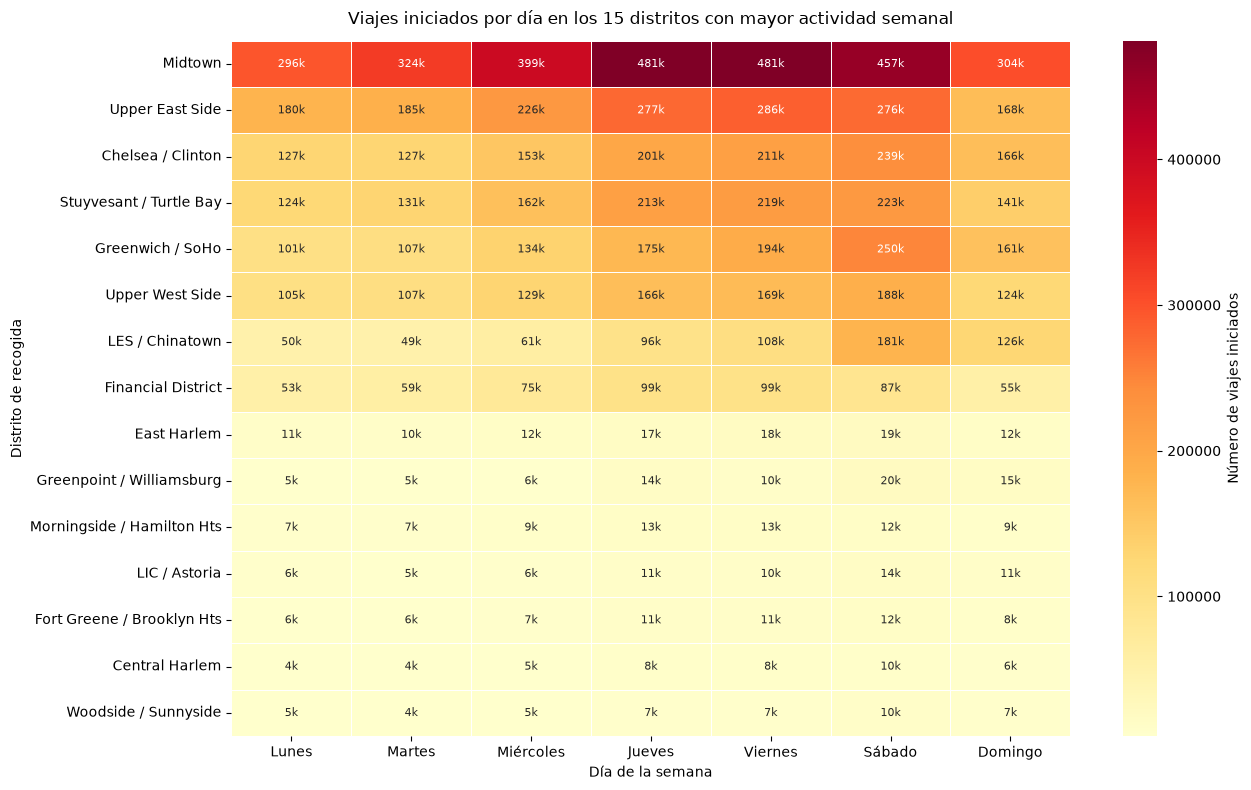

In [32]:
# ============================================================
# DISTRITOS CON MAYOR ACTIVIDAD
# ============================================================
districts_heatmap_pd = (
    district_activity_pd
    .head(15)
    .set_index('pickup_district')[DAYS_ORDER]
)


# ============================================================
# HEATMAP DE ACTIVIDAD POR DISTRITO Y DÍA
# ============================================================
districts_heatmap_plot_pd = districts_heatmap_pd.rename(index=DISTRICT_LABELS, columns=DAY_LABELS)

fig_districts, ax = plt.subplots(figsize=(13, 8))

annot = districts_heatmap_plot_pd.map(
    lambda value: (f'{value / 1_000:.0f}k' if value >= 1_000 else f'{value:.0f}')
)

sns.heatmap(
    districts_heatmap_plot_pd, ax=ax, cmap='YlOrRd', annot=annot, fmt='', linewidths=0.5,
    annot_kws={'size': 8}, cbar_kws={'label': 'Número de viajes iniciados'}
)

plt.title('Viajes iniciados por día en los 15 distritos con mayor actividad semanal', pad=12)

plt.xlabel('Día de la semana')
plt.ylabel('Distrito de recogida')

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()

_ = save_figure(fig_districts, '07_district_activity_heatmap', images_dir)

plt.show()

#### Distribución semanal por distrito

La intensidad semanal no evoluciona de forma idéntica en todos los distritos.

Midtown mantiene el mayor volumen durante todos los días, con niveles especialmente elevados entre jueves y sábado. Otros distritos muestran un componente más acusado de fin de semana: Greenwich / SoHo y Lower East Side / Chinatown incrementan notablemente su actividad el sábado.

El heatmap permite distinguir, por tanto, áreas con una demanda elevada y relativamente estable de otras cuya actividad está más vinculada a determinados momentos de la semana.

### 7.3. Flujos entre distritos

El enriquecimiento espacial permite analizar conjuntamente los distritos de origen y destino de los viajes.

Para mantener una representación interpretable se seleccionan los **15 distritos con mayor número total de recogidas** y se construye una matriz origen-destino mediante una agregación distribuida en Spark.

La matriz se representa desde dos perspectivas complementarias:

- **volumen absoluto de viajes**, que permite identificar los flujos con mayor número de desplazamientos;
- **distribución porcentual entre los destinos seleccionados**, que normaliza cada fila de la matriz y permite comparar el peso relativo de los principales destinos dentro del conjunto representado.

Esta segunda representación evita que los distritos con mayor actividad dominen completamente la escala visual y facilita la identificación de patrones relativos de movilidad.

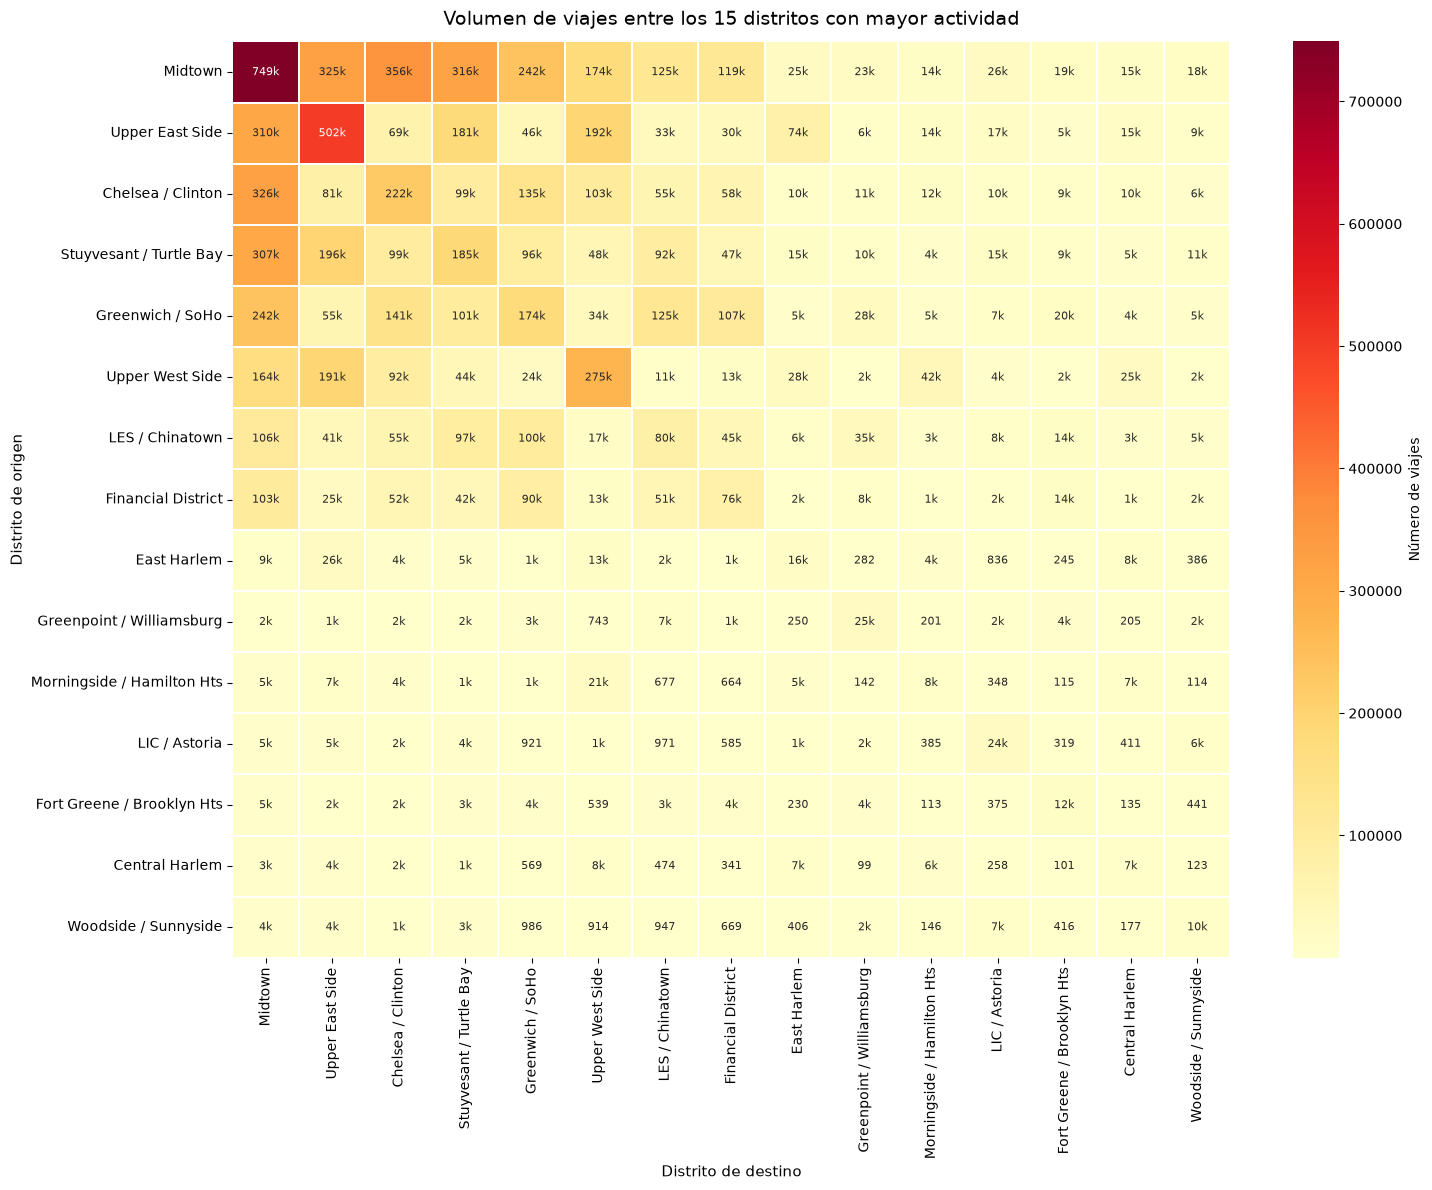

In [33]:
# ============================================================
# DISTRITOS PRINCIPALES
# ============================================================
top_districts = (
    district_activity_pd
    .head(15)['pickup_district']
    .tolist()
)

# ============================================================
# MATRIZ ORIGEN-DESTINO
# ============================================================
origin_destination_df = (
    spatial_analysis_df
    .filter(
        F.col('pickup_district').isin(top_districts)
        & F.col('dropoff_district').isin(top_districts)
    )
    .groupBy('pickup_district')
    .pivot('dropoff_district', top_districts)
    .count()
)

origin_destination_pd = (
    origin_destination_df
    .toPandas()
    .set_index('pickup_district')
    .reindex(index=top_districts, columns=top_districts)
    .fillna(0)
)

# ============================================================
# FLUJOS ORIGEN-DESTINO · VOLUMEN ABSOLUTO
# ============================================================
origin_destination_plot_pd = origin_destination_pd.rename(
    index=DISTRICT_LABELS, columns=DISTRICT_LABELS
)

fig_od_volume, _ = plot_origin_destination_heatmap(
    origin_destination_plot_pd,
    title=('Volumen de viajes entre los 15 distritos con mayor actividad')
)

_ = save_figure(fig_od_volume, '08_origin_destination_volume', images_dir)

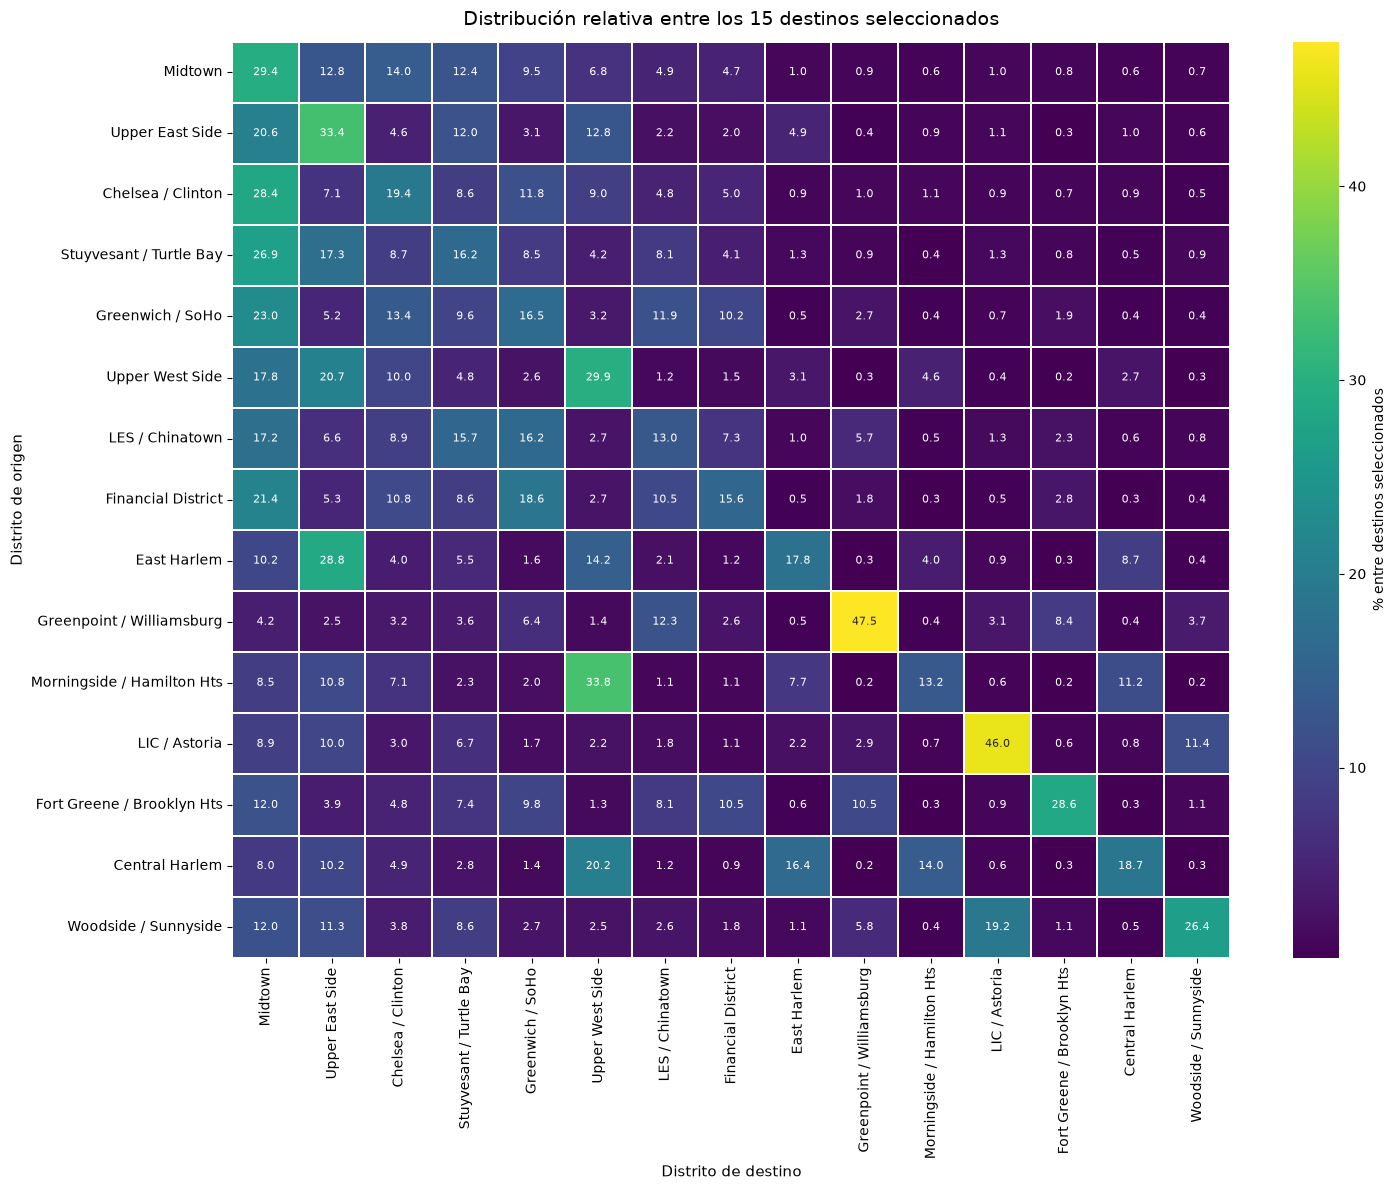

In [34]:
# ============================================================
# FLUJOS ORIGEN-DESTINO · DISTRIBUCIÓN
# ============================================================
fig_od_relative, _ = plot_origin_destination_heatmap(
    origin_destination_plot_pd,
    title=('Distribución relativa entre los 15 destinos seleccionados'),
    normalize=True
)

_ = save_figure(fig_od_relative, '09_origin_destination_relative', images_dir)

#### Estructura de los principales flujos

La matriz origen-destino confirma una fuerte concentración de desplazamientos dentro del núcleo de Manhattan.

En términos absolutos, **Midtown → Midtown** constituye el flujo individual de mayor volumen entre los distritos representados, con aproximadamente **749.000 viajes**, seguido por otros flujos internos y conexiones entre los principales distritos centrales.

La diagonal de la matriz es especialmente visible en varios territorios, indicando que una parte relevante de los viajes comienza y termina dentro del mismo distrito.

La representación normalizada aporta una lectura complementaria. Entre los 15 destinos seleccionados, los viajes internos representan aproximadamente el **47,5 %** de los destinos de Greenpoint / Williamsburg y el **46,0 %** en LIC / Astoria. En Upper East Side representan alrededor del **33,4 %** y en Midtown el **29,4 %**.

Estos porcentajes deben interpretarse exclusivamente dentro del conjunto de los **15 destinos representados**, no respecto al total de destinos posibles.

La primera matriz describe, por tanto, la **magnitud absoluta de los flujos**, mientras que la segunda permite comparar su **estructura relativa** independientemente del volumen total generado por cada distrito.

## 8. Arquitectura, rendimiento y ejecución Spark en local

### 8.1. Reutilización de DataFrames mediante caché

El pipeline reutiliza varios resultados intermedios cuyo recálculo implicaría volver a ejecutar transformaciones sobre el dataset distribuido.

Por este motivo se utiliza persistencia mediante `cache()` de forma selectiva:

- `nyc_trips_df`: DataFrame principal limpio y enriquecido, reutilizado a lo largo de prácticamente todo el análisis;
- `stats_df`: estadísticos distribuidos utilizados en la validación y en la representación de boxplots;
- `counts_and_distances_df`: agregación temporal reutilizada para obtener cuatro matrices diferentes;
- `spatial_analysis_df`: proyección reducida con la información territorial, reutilizada para evaluar la cobertura espacial, agregar viajes por distrito y construir la matriz origen-destino.

La caché no elimina el coste de la primera evaluación. Spark mantiene su modelo de ejecución perezosa y el DataFrame se materializa cuando se ejecuta la primera acción.

Para comprobar el efecto de la persistencia se compara el tiempo de dos acciones equivalentes sobre `nyc_trips_df`: la primera materializa el DataFrame y la segunda reutiliza el resultado almacenado.

In [35]:
# ============================================================
# RESUMEN DEL BENCHMARK DE CACHÉ
# ============================================================
cache_speedup = cache_first_pass_seconds / cache_second_pass_seconds

cache_time_saved = cache_first_pass_seconds - cache_second_pass_seconds

cache_reduction_pct = (1 - cache_second_pass_seconds / cache_first_pass_seconds) * 100

cache_summary_pd = pd.DataFrame({
    'Indicador': [
        'Primera materialización',
        'Reutilización desde caché',
        'Ahorro absoluto',
        'Reducción del tiempo',
        'Factor de aceleración',
        'Storage level'
    ],
    'Valor': [
        f'{cache_first_pass_seconds:.2f} s',
        f'{cache_second_pass_seconds:.2f} s',
        f'{cache_time_saved:.2f} s',
        f'{cache_reduction_pct:.2f} %',
        f'{cache_speedup:.1f}×',
        str(nyc_trips_df.storageLevel)
    ]
}).set_index('Indicador')

_ = save_table(cache_summary_pd, '04_cache_summary', tables_dir)

cache_summary_pd

,Valor
Indicador,
Primera materialización,18.36 s
Reutilización desde caché,0.17 s
Ahorro absoluto,18.19 s
Reducción del tiempo,99.06 %
Factor de aceleración,106.3×
Storage level,Disk Memory Deserialized 1x Replicated


#### Efecto de la persistencia

La ejecución confirma una reducción muy marcada del tiempo necesario para repetir una acción sobre `nyc_trips_df` una vez materializado en caché.

La primera acción debe evaluar el linaje completo y materializar el DataFrame persistido, mientras que la segunda puede reutilizar directamente ese resultado.

Los tiempos y el factor de aceleración mostrados en la tabla corresponden exclusivamente a la ejecución local actual. Su magnitud depende del hardware, la memoria disponible y el estado del sistema, por lo que no deben interpretarse como un benchmark general de Apache Spark.

### 8.2. Particiones, transformaciones narrow/wide y ejecución distribuida

Spark procesa los DataFrames mediante particiones distribuidas.

Las operaciones como `filter`, `select` o `withColumn` son principalmente transformaciones **narrow**: cada partición puede procesarse sin necesitar datos procedentes de otras particiones.

En cambio, operaciones como `groupBy`, `pivot`, `orderBy` y determinados `join` pueden requerir una redistribución de datos entre particiones (**shuffle**) y se comportan como transformaciones **wide**.

Las transformaciones son *lazy*: construyen el linaje y el plan de ejecución, pero el procesamiento no se materializa hasta que aparece una acción. En este notebook, operaciones como `count()`, `first()`, `toPandas()` o `write` desencadenan **jobs**, la ejecución del plan.

Cada job se divide en **stages**, y cada stage ejecuta múltiples **tasks**, normalmente una por partición procesada. Las operaciones que requieren shuffle suelen introducir una frontera entre stages.

A continuación se muestra el número de particiones de algunos DataFrames relevantes del pipeline y el valor configurado para `spark.sql.shuffle.partitions`.

In [36]:
partition_summary_pd = pd.DataFrame({
    'DataFrame': [
        'nyc_trips_df',
        'stats_df',
        'counts_and_distances_df',
        'spatial_analysis_df'
    ],
    'Particiones': [
        nyc_trips_df.rdd.getNumPartitions(),
        stats_df.rdd.getNumPartitions(),
        counts_and_distances_df.rdd.getNumPartitions(),
        spatial_analysis_df.rdd.getNumPartitions()
    ]
}).set_index('DataFrame')

print('spark.sql.shuffle.partitions:', spark.conf.get('spark.sql.shuffle.partitions'))

partition_summary_pd

spark.sql.shuffle.partitions: 8


,Particiones
DataFrame,
nyc_trips_df,16
stats_df,8
counts_and_distances_df,8
spatial_analysis_df,16


Los DataFrames principales conservan **16 particiones** en las fases directamente vinculadas al dataset de entrada, mientras que los resultados que atraviesan operaciones de agregación aparecen con **8 particiones**, en línea con la configuración de `spark.sql.shuffle.partitions`.

La diferencia ilustra el efecto de las operaciones *wide*: agregaciones, `pivot` y otras transformaciones que requieren shuffle pueden modificar el particionado del resultado.

### 8.3. Spark SQL y plan de ejecución

Spark SQL permite trabajar sobre los mismos DataFrames distribuidos mediante dos interfaces equivalentes: la API estructurada de DataFrames y consultas SQL.

Para ilustrar esta equivalencia se registra temporalmente el DataFrame principal como una vista SQL. La vista no duplica físicamente los datos; únicamente permite referenciarlos mediante SQL durante la sesión actual.

La consulta incluye tanto medias como medianas aproximadas. Esta comparación permite comprobar la sensibilidad de la media a valores extremos y refuerza el uso de estadísticos robustos en los análisis principales del proyecto. La consulta sigue siendo una transformación *lazy* y su resultado es otro DataFrame de Spark.

Como las operaciones de agregación no garantizan el orden de las filas resultantes, la consulta incorpora explícitamente el orden cronológico de los días de la semana.

Finalmente se inspecciona el plan físico generado por Spark. Esta representación permite relacionar la consulta declarativa con operaciones como agregaciones, intercambios de particiones (`Exchange`) y otras etapas que Catalyst incorpora al plan de ejecución.

In [37]:
# ============================================================
# VISTA TEMPORAL Y SPARK SQL
# ============================================================
nyc_trips_df.createOrReplaceTempView('nyc_trips')

daily_summary_sql_df = spark.sql("""
    SELECT
        day_of_week, COUNT(*) AS n_trips,

        ROUND(AVG(trip_distance), 2) AS avg_trip_distance,

        ROUND(percentile_approx(trip_distance, 0.5), 2) AS median_trip_distance,

        ROUND(percentile_approx(trip_distance,0.99), 2) AS p99_trip_distance,

        ROUND(AVG(speed), 2) AS avg_speed,

        ROUND(percentile_approx(speed, 0.5), 2) AS median_speed,

        ROUND(percentile_approx(speed, 0.99), 2) AS p99_speed

    FROM nyc_trips

    GROUP BY day_of_week

    ORDER BY CASE day_of_week
        WHEN 'lunes' THEN 1
        WHEN 'martes' THEN 2
        WHEN 'miercoles' THEN 3
        WHEN 'jueves' THEN 4
        WHEN 'viernes' THEN 5
        WHEN 'sabado' THEN 6
        WHEN 'domingo' THEN 7

    END
""")

daily_summary_sql_display_df = (
    daily_summary_sql_df.replace(to_replace=DAY_LABELS, subset=['day_of_week'])
)

daily_summary_sql_display_df.show(truncate=False)

+-----------+-------+-----------------+--------------------+-----------------+---------+------------+---------+
|day_of_week|n_trips|avg_trip_distance|median_trip_distance|p99_trip_distance|avg_speed|median_speed|p99_speed|
+-----------+-------+-----------------+--------------------+-----------------+---------+------------+---------+
|Lunes      |1197153|3.18             |1.8                 |18.97            |13.3     |11.65       |37.55    |
|Martes     |1233286|2.92             |1.78                |18.24            |12.47    |11.06       |35.8     |
|Miércoles  |1510473|5.51             |1.8                 |18.22            |26.6     |10.56       |35.04    |
|Jueves     |1953824|7.42             |1.87                |18.3             |21.97    |10.97       |36.16    |
|Viernes    |2004594|37.61            |1.8                 |18.4             |204.1    |10.47       |35.06    |
|Sábado     |2148723|8.67             |1.86                |18.1             |33.34    |11.64       |35.

In [38]:
# ============================================================
# PLAN DE EJECUCIÓN
# ============================================================
plan_buffer = io.StringIO()

with redirect_stdout(plan_buffer):
    daily_summary_sql_df.explain(mode='formatted')

plan_text = plan_buffer.getvalue().replace(str(project_dir), '<PROJECT_DIR>')

print(plan_text)

== Physical Plan ==
AdaptiveSparkPlan (12)
+- Sort (11)
   +- Exchange (10)
      +- ObjectHashAggregate (9)
         +- Exchange (8)
            +- ObjectHashAggregate (7)
               +- InMemoryTableScan (1)
                     +- InMemoryRelation (2)
                           +- * Project (6)
                              +- * Project (5)
                                 +- * Filter (4)
                                    +- Scan csv  (3)


(1) InMemoryTableScan
Output [3]: [trip_distance#20, day_of_week#39, speed#40]
Arguments: [trip_distance#20, day_of_week#39, speed#40]

(2) InMemoryRelation
Arguments: [VendorID#16, tpep_pickup_datetime#17, tpep_dropoff_datetime#18, passenger_count#19, trip_distance#20, pickup_longitude#21, pickup_latitude#22, RateCodeID#23, store_and_fwd_flag#24, dropoff_longitude#25, dropoff_latitude#26, payment_type#27, fare_amount#28, extra#29, mta_tax#30, tip_amount#31, tolls_amount#32, improvement_surcharge#33, total_amount#34, trip_duration_s#36L, pic

#### Lectura del plan de ejecución

La consulta SQL refuerza el diagnóstico realizado anteriormente.

Las medianas diarias de distancia permanecen aproximadamente entre **1,78 y 2,00 millas** y las medianas de velocidad entre **10,47 y 13,04 mph**. Del mismo modo, el percentil 99 de velocidad se mantiene aproximadamente entre **35 y 38 mph**.

En contraste, algunas medias aumentan de forma extrema —por ejemplo, la velocidad media del viernes alcanza 204,1 mph— debido a un número muy reducido de observaciones anómalas.

Esta diferencia confirma que la mediana y los percentiles proporcionan una descripción mucho más representativa del comportamiento habitual de los viajes en este dataset.

### 8.4. Persistencia de resultados en formato Parquet

Además del procesamiento en memoria, Spark proporciona una API uniforme de lectura y escritura de DataFrames.

Para comprobar este flujo se persiste el pequeño resumen generado mediante Spark SQL en formato **Parquet**.

A diferencia de CSV, Parquet almacena información sobre el esquema y utiliza un formato columnar especialmente adecuado para flujos analíticos. El resultado se vuelve a cargar mediante `DataFrameReader` para comprobar que puede incorporarse nuevamente al pipeline como un DataFrame de Spark.

In [39]:
# ============================================================
# ESCRITURA EN PARQUET
# ============================================================
# La escritura materializa el DataFrame y persiste el resultado
# en un formato columnar que conserva el esquema
daily_summary_parquet_path = outputs_dir / 'daily_summary_parquet'

(
    daily_summary_sql_df
    .write
    .mode('overwrite')
    .parquet(str(daily_summary_parquet_path))
)


# ============================================================
# LECTURA DEL RESULTADO
# ============================================================
# La relectura comprueba que el resultado puede incorporarse
# nuevamente al pipeline como DataFrame de Spark
daily_summary_parquet_df = (
    spark
    .read
    .parquet(str(daily_summary_parquet_path))
)


# ============================================================
# VALIDACIÓN DE LA LECTURA
# ============================================================
parquet_rows = daily_summary_parquet_df.count()

assert parquet_rows == 7
assert (daily_summary_parquet_df.columns == daily_summary_sql_df.columns)

daily_summary_parquet_df.printSchema()

print(f'Registros releídos desde Parquet: {parquet_rows}')

root
 |-- day_of_week: string (nullable = true)
 |-- n_trips: long (nullable = true)
 |-- avg_trip_distance: double (nullable = true)
 |-- median_trip_distance: double (nullable = true)
 |-- p99_trip_distance: double (nullable = true)
 |-- avg_speed: double (nullable = true)
 |-- median_speed: double (nullable = true)
 |-- p99_speed: double (nullable = true)

Registros releídos desde Parquet: 7


La escritura y posterior lectura en formato Parquet conserva las columnas y tipos necesarios para reutilizar el resultado como un nuevo DataFrame de Spark.

Este paso completa el flujo de procesamiento mostrando no solo transformaciones y análisis en memoria, sino también la persistencia de resultados en un formato columnar adecuado para cargas analíticas.

### 8.5. Portabilidad del entorno

La implementación utilizada en este notebook está preparada para ejecución local con Spark 4.1 y Apache Sedona 1.9.

Durante el desarrollo del proyecto también se trabajó con una adaptación para Databricks. La principal diferencia entre ambas versiones afecta a la configuración de la sesión Spark y al acceso a los datos, mientras que la lógica de transformación, agregación y análisis se mantiene conceptualmente equivalente.

La versión local se utiliza como referencia reproducible porque permite controlar el entorno y validar operaciones de persistencia que dependen de los recursos disponibles en la plataforma de ejecución.

## 9. Resultados principales

El pipeline procesa **11.489.716 viajes válidos** de taxis amarillos correspondientes a enero de 2015 e integra procesamiento distribuido, diagnóstico de calidad, análisis temporal, enriquecimiento geoespacial y evaluación del comportamiento de Spark.

Los principales resultados son:

- el comportamiento típico del viaje se sitúa en aproximadamente **1,83 millas** de distancia y **11,33 mph** de velocidad mediana;
- los registros extremos son extraordinariamente poco frecuentes: únicamente **354 viajes (0,0031 %)** superan las 100 mph, aunque su magnitud es suficiente para distorsionar fuertemente las medias;
- el volumen semanal aumenta durante la segunda mitad de la semana y alcanza su máximo el **sábado**, con aproximadamente **2,15 millones de viajes**;
- **Midtown** es el distrito con mayor actividad de recogida, con **2.742.852 viajes** durante el periodo;
- el enriquecimiento geoespacial asigna un distrito al **92,83 %** de los puntos de recogida y al **95,11 %** de los puntos de destino, disponiendo simultáneamente de origen y destino territorial en el **89,81 %** de los viajes;
- los spatial joins permiten transformar millones de coordenadas individuales en patrones territoriales y matrices origen-destino interpretables;
- la persistencia selectiva demuestra una reducción muy elevada del coste de acciones repetidas sobre DataFrames reutilizados, aunque la magnitud concreta depende del entorno de ejecución.

Los resultados describen exclusivamente el comportamiento observado en el dataset y periodo analizados y no deben interpretarse como una caracterización general de toda la movilidad de Nueva York.

In [40]:
# ============================================================
# RESUMEN DE RESULTADOS
# ============================================================
busiest_day_row = daily_trips_pd.loc[daily_trips_pd['n_trips_millions'].idxmax()]

top_district_row = district_activity_pd.iloc[0]

top_district_name = DISTRICT_LABELS.get(
    top_district_row['pickup_district'],
    top_district_row['pickup_district']
)

joint_coverage = float(spatial_coverage_pd.loc['Pickup y dropoff', 'Cobertura (%)'])

results_summary_pd = pd.DataFrame({
    'Indicador': [
        'Viajes analizados',
        'Comportamiento típico',
        'Registros > 100 mph',
        'Día con mayor volumen',
        'Distrito con mayor actividad',
        'Cobertura espacial conjunta',
        'Aceleración observada con caché'
    ],
    'Resultado': [
        f'{trip_count:,}',
        f'{distance_percentiles[0]:.2f} mi · {speed_percentiles[0]:.2f} mph',
        (
            f"{extreme_counts['speed_over_100']:,} · "
            f"{100 * extreme_counts['speed_over_100'] / trip_count:.4f} %"
        ),
        (
            f"{DAY_LABELS[busiest_day_row['day_of_week']]} · "
            f"{busiest_day_row['n_trips_millions']:.2f} M"
        ),
        f"{top_district_name} · {int(top_district_row['total_week']):,}",
        f'{joint_coverage:.2f} %',
        f'{cache_speedup:.1f}×'
    ],
}).set_index('Indicador')

_ = save_table(results_summary_pd, '05_results_summary', tables_dir)

results_summary_pd

,Resultado
Indicador,
Viajes analizados,"11,489,716"
Comportamiento típico,1.83 mi · 11.33 mph
Registros > 100 mph,354 · 0.0031 %
Día con mayor volumen,Sábado · 2.15 M
Distrito con mayor actividad,"Midtown · 2,742,852"
Cobertura espacial conjunta,89.81 %
Aceleración observada con caché,106.3×


### Cierre técnico · Liberación de recursos persistidos

Una vez completados todos los análisis, exportaciones y resúmenes finales, se liberan explícitamente los DataFrames persistidos mediante `unpersist()` para dejar disponibles los recursos asignados a su almacenamiento.

In [41]:
# ============================================================
# LIBERACIÓN DE DATAFRAMES PERSISTIDOS
# ============================================================
cached_dfs = {
    'nyc_trips_df': nyc_trips_df,
    'stats_df': stats_df,
    'counts_and_distances_df': counts_and_distances_df,
    'spatial_analysis_df': spatial_analysis_df
}

cache_status_before = {
    name: df.is_cached for name, df in cached_dfs.items()
}

for df in cached_dfs.values():
    df.unpersist(blocking=True)

cache_status_after = {
    name: df.is_cached for name, df in cached_dfs.items()
}

assert not any(cache_status_after.values())

cache_release_pd = pd.DataFrame({
    'DataFrame': list(cached_dfs.keys()),
    'Antes': [
        'Cacheado' if cache_status_before[name] else 'No cacheado'
        for name in cached_dfs
    ],
    'Después': [
        'Cacheado' if cache_status_after[name] else 'Liberado'
        for name in cached_dfs
    ]
}).set_index('DataFrame')

cache_release_pd

,Antes,Después
DataFrame,,
nyc_trips_df,Cacheado,Liberado
stats_df,Cacheado,Liberado
counts_and_distances_df,Cacheado,Liberado
spatial_analysis_df,Cacheado,Liberado


## 10. Conclusiones

Este proyecto desarrolla un flujo completo de análisis Big Data sobre **11.489.716 viajes de taxi amarillo de Nueva York correspondientes a enero de 2015**, utilizando **Apache Spark** como motor principal de procesamiento distribuido y **Apache Sedona** para incorporar análisis geoespacial.

La preparación de los datos se realiza íntegramente mediante PySpark DataFrames y funciones nativas de Spark SQL, utilizando un esquema explícito, transformaciones distribuidas y variables derivadas de carácter temporal y analítico. El diagnóstico de calidad demuestra que la distribución central de los datos es estable —con una distancia mediana de **1,83 millas** y una velocidad mediana de **11,33 mph**—, pero también revela un número muy reducido de observaciones extremas capaces de distorsionar de forma intensa las medias. Solo **354 registros (0,0031 %)** superan las 100 mph, lo que justifica la utilización de medianas y percentiles como medidas descriptivas principales sin alterar en esta versión el dataset reproducible de referencia.

El análisis temporal identifica diferencias claras a lo largo del día y de la semana. Las distancias medianas aumentan durante determinadas franjas nocturnas y de madrugada, mientras que las horas de mayor actividad presentan velocidades inferiores. El volumen crece durante la segunda mitad de la semana y alcanza su máximo el **sábado**, con aproximadamente **2,15 millones de viajes**.

La incorporación de Apache Sedona permite transformar las coordenadas individuales en unidades territoriales interpretables. Mediante `ST_Point`, `ST_Contains` y `broadcast joins`, el pipeline asigna un distrito al **92,83 %** de los puntos de recogida y al **95,11 %** de los destinos, alcanzando una cobertura conjunta del **89,81 %**. El análisis posterior muestra una fuerte concentración de actividad en el núcleo de Manhattan, con **Midtown** como principal distrito de origen con **2,74 millones de recogidas**.

Desde el punto de vista de arquitectura Spark, el proyecto integra funciones de ventana, percentiles distribuidos, agregaciones, `pivot`, persistencia selectiva, operaciones narrow y wide, análisis de particiones, Spark SQL y revisión del plan físico de ejecución. La reutilización de DataFrames persistidos reduce de forma muy marcada el coste de acciones repetidas, y la escritura y relectura en formato Parquet completa el ciclo de procesamiento y persistencia de resultados.

El proyecto mantiene deliberadamente separadas las operaciones distribuidas de las tareas locales de presentación. Los millones de registros permanecen en Spark y únicamente resultados agregados o muestras de pequeño tamaño se trasladan a Pandas, GeoPandas, Folium o Matplotlib. Esta separación permite conservar la escalabilidad del procesamiento sin renunciar a una interpretación gráfica accesible.

La versión local constituye la implementación reproducible de referencia. El proyecto se complementa con una segunda versión orientada a **calidad de datos y depuración de valores extremos**, en la que se compara el comportamiento analítico antes y después de aplicar criterios explícitos de depuración.

A partir de ambas implementaciones locales se desarrolla posteriormente la adaptación para **Databricks Serverless**, manteniendo la lógica analítica validada y ajustando la configuración del entorno, el acceso y persistencia de los datos, el procesamiento geoespacial y la estrategia de reutilización a las capacidades de la plataforma cloud.